# DAX-Renditeschwankungen und Value at Risk: GARCH vs. LSTM

**Autor:** Marc Krümpelmann · **Format:** Überarbeitete Portfolio-Fassung eines Universitätsprojekts

Dieses Notebook zeigt eine durchgehende Analyse von historischen Kursdaten über zeitliche Modellauswahl und Tagesprognosen bis zum VaR-Backtesting. Verglichen werden ein GARCH-Modell mit Student-t-Innovationen und ein LSTM für absolute Tagesrenditen mit anschließender t-Kalibrierung.

**Zentrales Ergebnis des dokumentierten Laufs:** Bei 550 Bewertungstagen werden beide VaR-Modelle im Kupiec-, Unabhängigkeits- und Conditional-Coverage-Test auf dem 5-%-Niveau nicht verworfen. Daraus folgt weder eine Bestätigung ihrer Korrektheit noch eine statistisch belegte Überlegenheit des LSTM.

**Leseführung:** Kurze Absätze erläutern Entscheidungen und Ergebnisse; Tabellen und Stichpunkte fassen Konfiguration und Grenzen zusammen. Die Codeausgaben liefern die jeweils berechneten Kennzahlen. Die unten dokumentierten VaR-Werte stammen aus dem lokal ausgeführten und geprüften Lauf; sie werden durch eine erneute Ausführung nicht automatisch im Markdown aktualisiert.


In [ ]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Statistik & Zeitreihen
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf
from arch import arch_model
from scipy.stats import t, chi2

# Machine Learning & Preprocessing
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error

# Deep Learning (Keras/TensorFlow)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

#MAE & RMSE
from sklearn.metrics import mean_absolute_error, mean_squared_error




/Users/marc/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35:NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020


## Projektprofil

- **Businessfrage:** Liefert ein komplexeres neuronales Netz gegenüber einem sparsamen ökonometrischen Modell einen erkennbaren Nutzen für tägliche Risikoprognosen?
- **Werkzeuge:** Python, pandas, NumPy, arch, TensorFlow/Keras, scikit-learn, SciPy und Matplotlib.
- **Gezeigte Fähigkeiten:** Datenprüfung, Zeitreihenaufbereitung, chronologische Validierung, Modellvergleich, Visualisierung und vorsichtige Interpretation statistischer Tests.


# Inhaltsverzeichnis 

- [1. Einleitung](#1-einleitung)
- [2. Konzeptioneller Rahmen](#2-konzeptioneller-rahmen)
- [3. Methodik](#3-methodik)
- [4. Datenbeschreibung und deskriptive Statistik](#4-datenbeschreibung-und-deskriptive-statistik)
- [5. Ergebnisse](#5-ergebnisse)
- [6. Diskussion](#6-diskussion)
- [7. Fazit](#7-fazit)
- [Literaturverzeichnis](#literaturverzeichnis)


# 1. Einleitung

Ziel ist der Vergleich zweier Ansätze zur Modellierung täglicher DAX-Renditeschwankungen und ihrer Verwendung für einen Ein-Tages-VaR mit 95 % Konfidenzniveau. GARCH bildet bedingte Varianz mit einer expliziten statistischen Struktur ab; das LSTM lernt aus Sequenzen vergangener absoluter Renditen.

Die Fragestellung lautet: **Welchen zusätzlichen Nutzen zeigt das LSTM gegenüber GARCH im gewählten Datensatz und Bewertungszeitraum?** Betrachtet werden Fehlermaße gegenüber absoluten Renditen und die Häufigkeit sowie zeitliche Struktur von VaR-Überschreitungen.

Es handelt sich um ein abgegrenztes Portfolio-Projekt. Es demonstriert einen nachvollziehbaren Analyseprozess und bewertet die Grenzen der Ergebnisse; es entwickelt kein produktionsreifes oder regulatorisch validiertes Risikomodell.


# 2. Konzeptioneller Rahmen

## 2.1. Eigenschaften von Finanzzeitreihen

Tägliche Renditen sind häufig nur schwach linear vorhersehbar. Ein Random Walk beschreibt dabei näherungsweise den Kurs- beziehungsweise Log-Kursprozess, nicht die Renditen selbst. Aus geringer Renditeautokorrelation allein lässt sich weder ein Random Walk noch Markteffizienz beweisen.

Vorhersehbare **Schwankungsniveaus** sind damit vereinbar: Auf turbulente Phasen folgen häufig weitere turbulente Tage. Diese Volatilitätscluster motivieren die Modellierung bedingter Varianz. Die genaue Größe einer einzelnen Tagesbewegung bleibt trotzdem unsicher. Außerdem treten bei Finanzrenditen häufig stärkere Verteilungsränder als bei einer Normalverteilung auf (Cont, 2001).


## 2.2. Volatilitätsmodellierung: Von klassischen Ansätzen zum neuronalen Netz

**GARCH** beschreibt die bedingte Varianz anhand vergangener quadrierter Innovationen und vergangener Varianzen. Seine sparsame Parametrisierung macht es zu einem gut interpretierbaren Vergleichsmodell (Bollerslev, 1986).

**LSTM** ist eine rekurrente Netzarchitektur für Sequenzdaten. Ihre Speicher- und Gate-Struktur erlaubt es, Informationen aus zurückliegenden Zeitschritten zu verarbeiten (Hochreiter & Schmidhuber, 1997). Im vorliegenden Projekt bekommt das Netz ausschließlich absolute historische Renditen als Eingabe. Seine Flexibilität garantiert keinen Prognosevorteil gegenüber einfacheren Modellen.


## 2.3. Das Konzept des Value at Risk (VaR)

Der Ein-Tages-VaR bei 95 % wird hier als **unteres 5-%-Quantil der prognostizierten Log-Renditeverteilung** dargestellt:

$$q_{t,0.05}=F^{-1}_{t\mid t-1}(0.05).$$

Die dargestellte Größe ist eine typischerweise negative Renditeschwelle in Prozent, kein positiver Verlustbetrag in Euro. Eine Überschreitung des Verlustschwellenwerts liegt vor, wenn die realisierte Rendite darunter fällt:

$$I_t=\mathbf{1}\{r_t<q_{t,0.05}\}.$$

Bei korrekter bedingter Abdeckung beträgt die erwartete Überschreitungsquote 5 %. Der VaR begrenzt nicht den maximal möglichen Verlust und beschreibt nicht die durchschnittliche Verlusthöhe jenseits der Schwelle.


## 2.4. Stand der Forschung

Die Grundlagen von GARCH, LSTM und VaR-Backtesting sind in der unten aufgeführten Literatur dokumentiert. Dieses Projekt nutzt sie als methodischen Rahmen und prüft den Modellvergleich an einer einzelnen DAX-Zeitreihe.

Ein allgemeiner Vorrang von Deep Learning wird nicht vorausgesetzt. Ergebnisse hängen unter anderem von Zielgröße, Marktphase, Datenmenge, Verteilungsannahmen und Aktualisierungsstrategie ab.


## 2.5. Erwartungen an den Modellvergleich


Zwei Erwartungen strukturieren die Auswertung:

- **H1 – Fehlermaße:** Das LSTM könnte absolute Tagesrenditen gemessen an MAE und RMSE genauer approximieren als die direkt verwendete GARCH-Standardabweichung. Wegen der unterschiedlichen Prognoseziele ist dies ein explorativer Proxy-Vergleich, kein eindeutiger Test überlegener Volatilitätsprognosen.
- **H2 – VaR:** Die zusätzliche Flexibilität des LSTM könnte zu einer besseren VaR-Abdeckung führen. Die Backtests prüfen jedoch jedes Modell gegen seine jeweilige Nullhypothese; sie sind keine direkten Überlegenheitstests zwischen den Modellen.

Aus der Komplexität eines Modells wird keine höhere Prognosequalität abgeleitet.


# 3. Methodik

Die Auswertung trennt Modellauswahl, finales Refit und abschließende Bewertung chronologisch. Sämtliche Prognosen für einen Zieltag verwenden als Eingabe nur zuvor beobachtete Renditen. Die letzten 20 % werden im überarbeiteten Code weder für die Auswahl der GARCH-Ordnung noch für die LSTM-Epochenwahl verwendet.


## 3.1. Der GARCH(p,q) Prozess

In der im Paket `arch` verwendeten Konvention bezeichnet $p$ die Zahl der ARCH-/Schock-Lags und $q$ die Zahl der GARCH-/Varianz-Lags:

$$r_t=\mu+\epsilon_t,\qquad \epsilon_t=\sigma_t z_t,$$

$$\sigma_t^2=\omega+\sum_{i=1}^{p}\alpha_i\epsilon_{t-i}^2+\sum_{j=1}^{q}\beta_j\sigma_{t-j}^2.$$

Die Innovationen $z_t$ folgen einer auf Varianz eins standardisierten Student-t-Verteilung mit $\nu>2$. Die Verteilungsannahme betrifft die standardisierten Innovationen, nicht die Varianz selbst. Für das hier eingesetzte GARCH(1,1) sichert $\alpha_1+\beta_1<1$ bei den üblichen Positivitätsbedingungen eine endliche unbedingte Varianz; strikte Stationarität ist davon zu unterscheiden.

Neun Kombinationen mit $p,q\in\{1,2,3\}$ werden auf den ersten 70 % geschätzt. AIC und BIC dokumentieren die Anpassung unter Berücksichtigung der Parameterzahl. Die endgültige Auswahl erfolgt anhand des niedrigsten Prognose-RMSE auf den folgenden 10 %. Danach bleibt die Modellordnung festgelegt.


## 3.2. Long Short-Term Memory (LSTM) Netzwerke

Das LSTM verarbeitet pro Prognose die letzten 120 absoluten Tagesrenditen. Seine Gewichte werden zunächst anhand der ersten 70 % angepasst; die folgenden 10 % steuern die Epochenwahl. Nach dieser Auswahl wird ein neu initialisiertes Netz auf den ersten 80 % trainiert.


**Funktionsweise:** Forget-, Input- und Output-Gates steuern, welche Informationen gespeichert, aktualisiert und ausgegeben werden.


Die Architektur wird direkt im Code definiert und über die Modellzusammenfassung dokumentiert; eine zusätzliche lokale Bilddatei ist nicht erforderlich.


| Einstellung | Umsetzung |
|---|---|
| Eingabe | 120 vergangene absolute Log-Renditen, ein Merkmal pro Tag |
| Rekurrente Schicht | LSTM mit 25 Einheiten |
| Ausgabe | Eine lineare Dense-Einheit |
| Dropout | 0,0; damit keine Dropout-Regularisierung |
| Optimierung | Adam, Lernrate 0,001 |
| Verlust | MSE auf skalierten absoluten Renditen |
| Batch-Größe | 25; keine zufällige Umsortierung |
| Trainingsdauer | Bis zu 1.000 Epochen; Early-Stopping-Patience 10 |

Diese Einstellungen sind Projektentscheidungen und werden nicht als optimal nachgewiesen. Die lineare Ausgabe garantiert keine positiven Prognosen. Deshalb prüft der VaR-Code die verwendeten LSTM-Skalen explizit und bricht bei nichtpositiven Werten ab.


## 3.3. Backtesting Verfahren für VaR Prognosen

Die Backtests verwenden $I_t=1$, wenn die Rendite die untere Prognoseschwelle unterschreitet. Das Testniveau beträgt jeweils 5 %.

| Test | Nullhypothese | Asymptotische Referenz |
|---|---|---|
| Kupiec / Unconditional Coverage | Überschreitungswahrscheinlichkeit entspricht 5 % | $\chi^2(1)$ |
| Christoffersen / Independence | Keine Abhängigkeit erster Ordnung zwischen aufeinanderfolgenden Überschreitungsindikatoren | $\chi^2(1)$ |
| Conditional Coverage | Gemeinsame Prüfung von Abdeckung und Unabhängigkeit | $\chi^2(2)$ |

Der gemeinsame Test addiert die beiden Likelihood-Ratio-Statistiken. Die Implementierung rechnet in Log-Likelihoods, um numerischen Unterlauf zu vermeiden. Auch null beziehungsweise ausschließlich Überschreitungen gehen korrekt in den Kupiec-Test ein. Fehlt einer der Übergangszustände, wird der Unabhängigkeitstest als nicht auswertbar gekennzeichnet.

**Interpretation:** Ein p-Wert ab 0,05 bedeutet, dass die Nullhypothese nicht verworfen wird. Das beweist weder die Korrektheit des Modells noch seine Überlegenheit. Gerade bei wenigen Überschreitungen ist die Aussagekraft asymptotischer Tests begrenzt (Kupiec, 1995; Christoffersen, 1998).


# 4. Datenbeschreibung und deskriptive Statistik

Die Daten enthalten DAX-Schlussstände (`.GDAXI`) vom **02.01.2015 bis 31.10.2025** aus einem Export von LSEG Workspace. Vor der Renditeberechnung werden Datum, fehlende Werte und positive Preise geprüft.

- Ursprünglicher Export: **2.826 Zeilen**.
- Entfernte exakte Duplikate: **75 Zeilen**.
- Bereinigte tägliche Kursbeobachtungen: **2.751**.
- Nach Bildung der ersten Differenz: **2.750 Log-Renditen**.

Die Berechnung erfolgt in Prozent:

$$r_t=100\ln(P_t/P_{t-1}).$$

Der DAX-Stand ist ein Indexstand, kein Aktienkurs in Euro. Die Transformation garantiert keine Stationarität. Widersprüchliche Preise für denselben Tag werden nicht stillschweigend zusammengefasst, sondern führen zu einem Fehler.

**Datenbereitstellung:** Die CSV wird lokal eingelesen; ein API-Zugang ist für die Ausführung nicht erforderlich. Eine öffentliche Weitergabe des LSEG-Exports setzt entsprechende Nutzungsrechte voraus; die Datenquelle allein ist keine Weitergabelizenz.


In [3]:
# Load and validate raw prices before calculating returns.
from pathlib import Path
candidates = [Path('data/DAX_Data.csv'), Path('DAX_Data.csv'), Path('../upload/DAX_Data.csv')]
data_path = next((p for p in candidates if p.exists()), None)
if data_path is None:
    raise FileNotFoundError('Place DAX_Data.csv in data/ or beside this notebook.')
df = pd.read_csv(data_path)
df['Date'] = pd.to_datetime(df['Date'], errors='raise')
df['Price Close'] = pd.to_numeric(df['Price Close'], errors='raise')
assert df[['Instrument', 'Date', 'Price Close']].notna().all().all()
assert (df['Price Close'] > 0).all()
raw_count = len(df)
df = df.drop_duplicates().copy()
if df.duplicated(['Instrument', 'Date']).any():
    raise ValueError('Conflicting prices for the same instrument/date.')
assert df['Instrument'].nunique() == 1, 'This notebook expects one instrument.'
print(f'Exact duplicate rows removed: {raw_count - len(df)}; price observations: {len(df)}')


Exact duplicate rows removed: 75; price observations: 2751


,Instrument,Date,Price Close,Log Return,Log Return (%)
0,.GDAXI,2015-01-02,9764.73,NaN,NaN
1,.GDAXI,2015-01-05,9473.16,-0.030314,-3.031438
2,.GDAXI,2015-01-06,9469.66,-0.000370,-0.036953
3,.GDAXI,2015-01-07,9518.18,0.005111,0.511065
4,.GDAXI,2015-01-08,9837.61,0.033009,3.300914
...,...,...,...,...,...
2821,.GDAXI,2025-10-27,24308.78,0.002838,0.283798
2822,.GDAXI,2025-10-28,24278.63,-0.001241,-0.124106
2823,.GDAXI,2025-10-29,24124.21,-0.006381,-0.638064
2824,.GDAXI,2025-10-30,24118.89,-0.000221,-0.022055


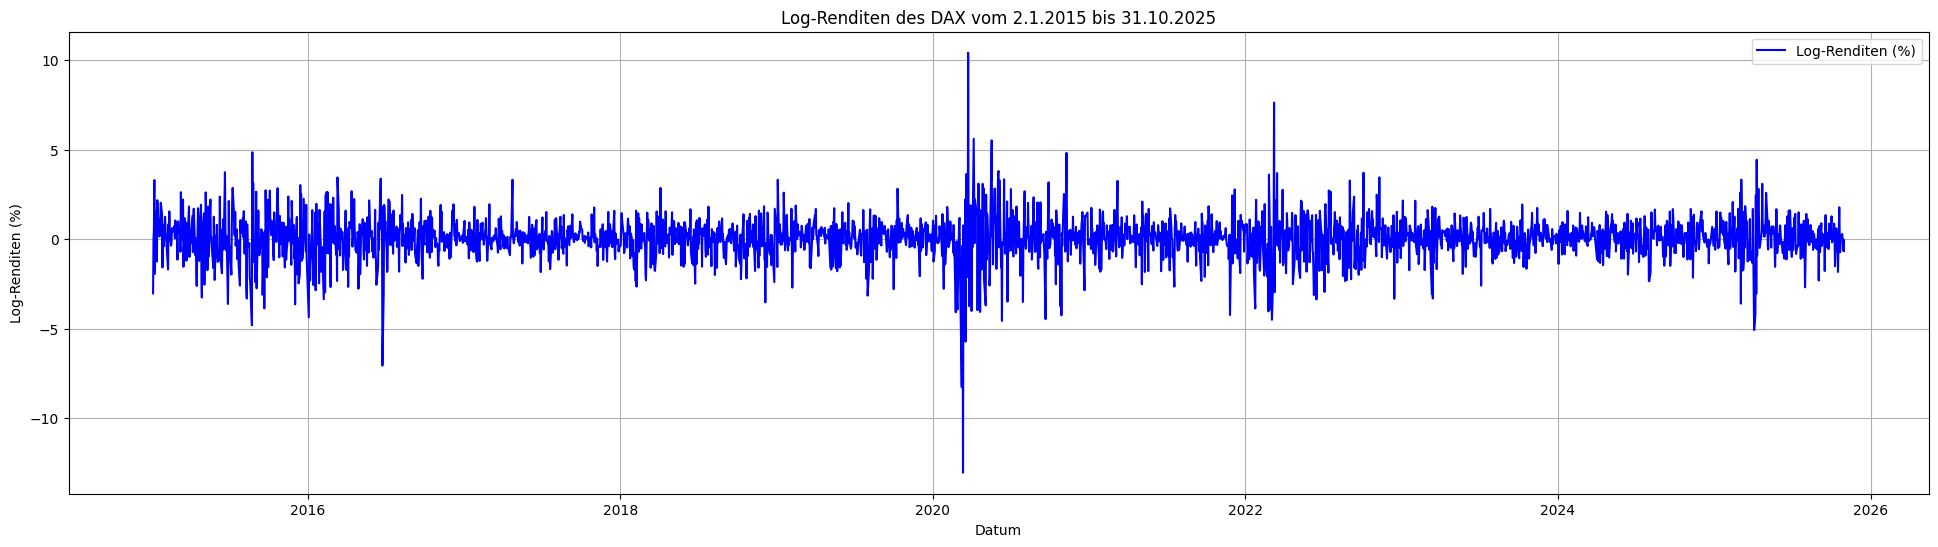

In [4]:
##Dax Daten einlesen aus cvs Datei

#Sicherstellung, dass Datumsspalte vom Typ "Datum" ist.
df['Date'] = pd.to_datetime(df['Date'])

# Nach Instrument und Datum (aufsteigend) sortieren
# Ältestes Datum zuerst, damit die Berechnung (heute - gestern) / gestern stimmt.
df = df.sort_values(by=['Instrument', 'Date'], ascending=True)

# Logarithmische Rendite pro Instrument berechnen

df['Log Return'] = df.groupby('Instrument')['Price Close'].transform(lambda x: np.log(x).diff())
df['Log Return (%)'] = df['Log Return'] * 100


display(df)

##Plot der logarithmischen Renditen
plt.figure(figsize=(24, 6))
plt.plot(df['Date'], df['Log Return (%)'], label='Log-Renditen (%)', color='blue')
plt.title('Log-Renditen des DAX vom 2.1.2015 bis 31.10.2025')
plt.xlabel('Datum')
plt.ylabel('Log-Renditen (%)')
plt.legend()
plt.grid(True)
plt.show()



Die Grafik macht wechselnde Schwankungsphasen und einzelne extreme Tagesbewegungen sichtbar, darunter den Ausschlag während der Corona-Krise 2020. Das ist mit Volatilitätsclustern vereinbar; eine visuelle Betrachtung allein ist kein statistischer Nachweis und identifiziert keine Ursachen einzelner Bewegungen.

Die folgende Ausgabe beschreibt die bereinigten Renditen quantitativ.


Deskriptive Statistik der Log-Renditen (%):
count    2750.000000
mean        0.032638
std         1.209236
min       -13.054860
25%        -0.495485
50%         0.077917
75%         0.659082
max        10.414289
Name: Log Return (%), dtype: float64


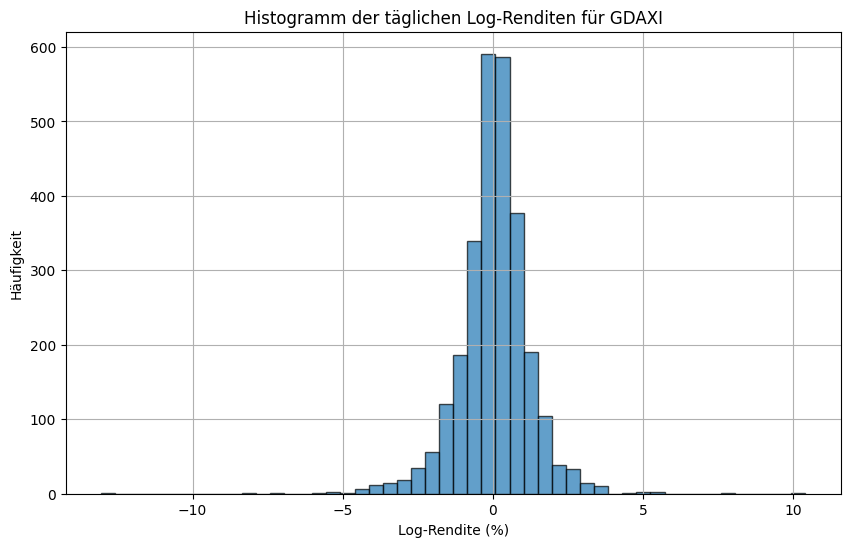

In [5]:
#Deskriptive Statistik der Log-Renditen 
df['Log Return (%)'].describe()

#Histogramm und Deksriptive Statistik der Log-Renditen anzeigen
print("Deskriptive Statistik der Log-Renditen (%):")
print(df['Log Return (%)'].describe())  

#Histogramm der Log-Renditen erstellen
plt.figure(figsize=(10, 6))
plt.hist(df['Log Return (%)'].dropna(), bins=50, edgecolor='k', alpha=0.7)
plt.title('Histogramm der täglichen Log-Renditen für GDAXI')
plt.xlabel('Log-Rendite (%)')
plt.ylabel('Häufigkeit')
plt.grid(True)
plt.show()

Die deskriptiven Kennzahlen beziehen sich auf **2.750 bereinigte Renditen**. Mittelwert, Standardabweichung und Extremwerte sind der unmittelbar darüber stehenden Ausgabe zu entnehmen.

Ein kleiner Mittelwert bei erheblich größeren Tagesausschlägen verdeutlicht, dass durchschnittliche Richtung und Schwankungsstärke unterschiedliche Aspekte der Zeitreihe beschreiben. Das Histogramm dient der explorativen Beschreibung; Aussagen über Verteilungsschwänze erfordern mehr als die Betrachtung einzelner Extremwerte.


### Chronologische Aufteilung und Refit

| Abschnitt | Renditen | Zeitraum | Aufgabe |
|---|---:|---|---|
| Erste 70 % | 1.925 | 05.01.2015–09.08.2022 | GARCH-Kandidaten schätzen; LSTM trainieren |
| Folgende 10 % | 275 | 10.08.2022–04.09.2023 | GARCH-Ordnung über Prognose-RMSE und LSTM-Epochenzahl über Validierungs-MSE auswählen |
| Letzte 20 % | 550 | 05.09.2023–31.10.2025 | Abschließender Modellvergleich und VaR-Backtesting |

**Warum das finale Refit auf 80 %?** Nach Abschluss der Auswahl stehen GARCH-Ordnung und LSTM-Epochenzahl fest. Die ersten beiden Abschnitte können nun zusammengeführt werden, um die Modellparameter mit allen vor Beginn der Bewertung verfügbaren Beobachtungen neu zu schätzen. Der 10-%-Abschnitt wird damit zu Refit-Daten; er ist anschließend keine unabhängige Validierung mehr. Die letzten 20 % bleiben von dieser Auswahl und initialen Parameterschätzung ausgeschlossen.

Während der Bewertung wird GARCH vor jedem Zieltag auf der wachsenden Historie neu geschätzt (**Expanding Window**). Das LSTM behält nach dem Refit seine Gewichte; sein Eingabefenster wandert täglich weiter und enthält zuletzt beobachtete Renditen. Verglichen werden damit bewusst unterschiedliche Aktualisierungsstrategien.

Die 120 benötigten historischen Werte werden über Abschnittsgrenzen hinweg übernommen. Dadurch entfällt kein Zieltag in Validierung und Bewertung; innerhalb des anfänglichen LSTM-Trainings entstehen 1.805 Sequenzen. Skalierer werden ausschließlich auf den jeweils verfügbaren Trainingsdaten angepasst. Werte außerhalb des Trainingsbereichs müssen nach der Transformation nicht innerhalb von [0,1] liegen.

**Wichtige Einschränkung:** Der letzte Zeitraum wurde bereits in der ursprünglichen Seminarfassung betrachtet. Er ist im überarbeiteten Code von der Auswahl getrennt, aber kein vollständig ungesehener neuer Holdout. Aus Kompatibilitätsgründen heißt dieser abschließende Bewertungsabschnitt im Code weiterhin `val_df`.

### Was MAE und RMSE hier messen

Beide Prognosereihen werden mit den absoluten Renditen verglichen. Das LSTM wird direkt auf diese Größe trainiert; GARCH liefert eine bedingte Standardabweichung. Absolute Rendite und Standardabweichung sind **nicht identisch**. Die Kennzahlen sind daher ein deskriptiver Vergleich mit einem verrauschten Proxy und erlauben allein keinen eindeutigen Nachweis überlegener Prognosen der unbeobachteten Volatilität.


In [6]:
#Daten so aufbereiteen, dass nur die 'Log Return'-Spalte für die Zeitreihenanalyse verwendet wird.

#'Date'-Spalte als Index setzen. (wichtig für statsmodels und Zeitreihenanalyse)
df = df.set_index('Date')

# Nur die 'Log Return'-Spalte auswählen
# Die erste Zeile hat einen "Missing value" und wird entfernt.

log_returns_series = df['Log Return (%)'].dropna()

In [7]:
# Chronological 70/10/20 split: training / early stopping / final evaluation.
# val_df remains the legacy variable name for FINAL EVALUATION throughout the notebook.
# This period was inspected in the seminar; it is not a genuinely unseen holdout.
train_end = len(log_returns_series) * 70 // 100
eval_start = len(log_returns_series) * 80 // 100
fit_df = log_returns_series.iloc[:train_end]
early_stop_df = log_returns_series.iloc[train_end:eval_start]
train_df = log_returns_series.iloc[:eval_start]  # Full development period for final fitting.
val_df = log_returns_series.iloc[eval_start:]   # Reserved final comparison period.
assert fit_df.index.max() < early_stop_df.index.min()
assert early_stop_df.index.max() < val_df.index.min()
for label, part in [('Training', fit_df), ('Early stopping', early_stop_df), ('Final evaluation', val_df)]:
    print(f'{label}: {len(part)} returns, {part.index.min().date()} to {part.index.max().date()}')


Training: 1925 returns, 2015-01-05 to 2022-08-09
Early stopping: 275 returns, 2022-08-10 to 2023-09-04
Final evaluation: 550 returns, 2023-09-05 to 2025-10-31


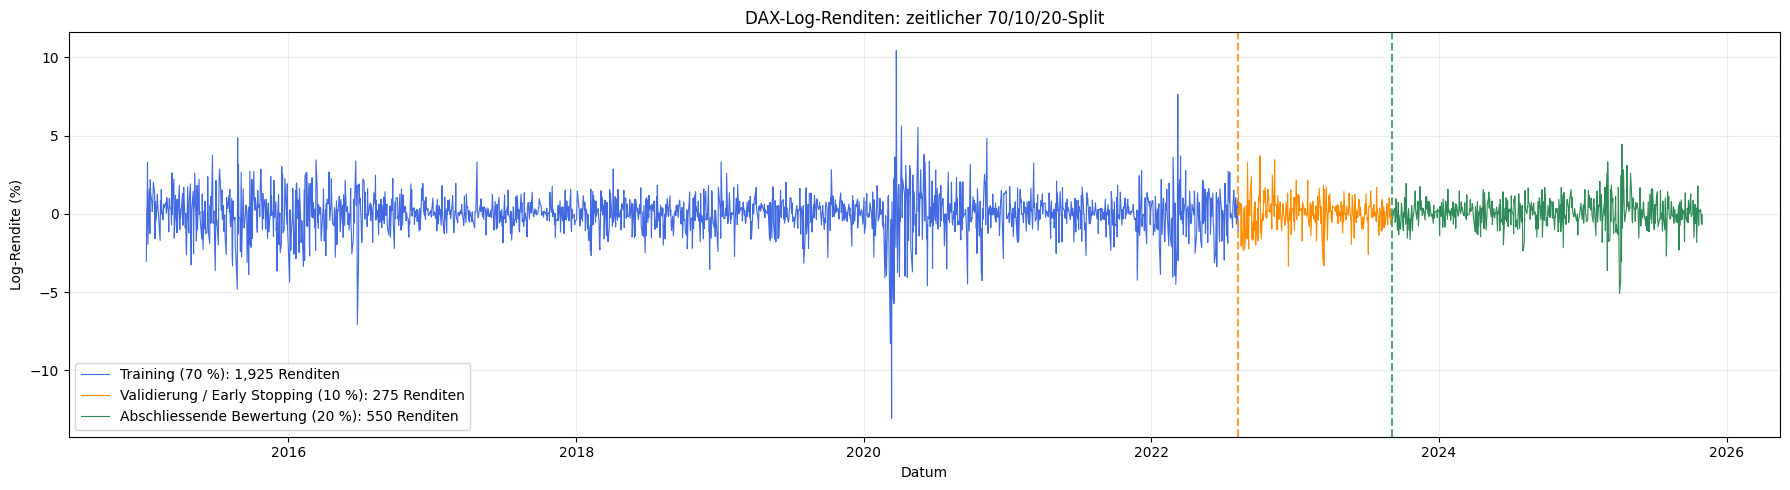

In [8]:
# Chronologische Abschnitte fuer Training, Early Stopping und Bewertung.
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(18, 5))
for series, label, color in [
    (fit_df, 'Training (70 %)', 'royalblue'),
    (early_stop_df, 'Validierung / Early Stopping (10 %)', 'darkorange'),
    (val_df, 'Abschliessende Bewertung (20 %)', 'seagreen'),
]:
    ax.plot(series.index, series, label=f'{label}: {len(series):,} Renditen', color=color, linewidth=0.8)
ax.axvline(early_stop_df.index[0], color='darkorange', linestyle='--', alpha=0.8)
ax.axvline(val_df.index[0], color='seagreen', linestyle='--', alpha=0.8)
ax.set(title='DAX-Log-Renditen: zeitlicher 70/10/20-Split', xlabel='Datum', ylabel='Log-Rendite (%)')
ax.legend(loc='lower left')
ax.grid(True, alpha=0.25)
fig.tight_layout()
plt.show()


Die folgende Tabelle stellt alle drei Zeitabschnitte getrennt gegenüber.


In [9]:
# Statistiken fuer die drei getrennten Zeitabschnitte.
comparison = pd.DataFrame({
    'Training (70 %)': fit_df.describe(),
    'Early Stopping (10 %)': early_stop_df.describe(),
    'Abschliessende Bewertung (20 %)': val_df.describe(),
})
print(comparison.loc[['count', 'mean', 'std', 'min', 'max']])
print('Finales Refit: Training und Early-Stopping-Abschnitt zusammen (erste 80 %).')


       Training (70 %)  Early Stopping (10 %)  Abschliessende Bewertung (20 %)
count      1925.000000             275.000000                       550.000000
mean          0.016961               0.056838                         0.075406
std           1.302427               1.009731                         0.930182
min         -13.054860              -3.332677                        -5.079905
max          10.414289               3.706218                         4.434084
Finales Refit: Training und Early-Stopping-Abschnitt zusammen (erste 80 %).


Die Streuung unterscheidet sich zwischen den Abschnitten. Insbesondere enthält das Training die Corona-Krise und damit starke Ausschläge, die im MSE erheblich ins Gewicht fallen. Trainings- und Validierungsfehler sind deshalb nicht unabhängig von den jeweiligen Marktphasen zu interpretieren.


# 5. Ergebnisse

Die folgenden Abschnitte verbinden Modellkonfiguration, Diagnose, Prognoseausgaben und die wirtschaftliche Einordnung des VaR-Backtestings.


## 5.1. Ergebnisse des GARCH-Modells

### 5.1.1. GARCH Spezifikation 

Die GARCH-Rastersuche umfasst neun Kombinationen mit $p,q=1,2,3$. Jeder Kandidat wird zunächst auf den ersten 70 % geschätzt und anschließend über alle 275 Validierungstage mit täglich wachsender Historie geprüft.

**Auswahlkriterium ist der kleinste Validierungs-RMSE gegenüber absoluten Renditen.** AIC/BIC stammen ausschließlich aus der initialen 70-%-Schätzung und dienen als ergänzende Diagnosen; BIC löst lediglich exakte RMSE-Gleichstände auf. Nicht konvergierte Kandidaten werden ausgeschlossen, statt sie auf einem verkürzten Zeitraum zu bewerten. Die letzten 20 % haben auf die Auswahl keinen Einfluss.


In [11]:
# GARCH-Auswahl: Training 70 %, Prognosevalidierung 10 %, Bewertung 20 %.
# arch-Konvention: p = ARCH-/Schock-Lags, q = GARCH-/Varianz-Lags.
# Auswahlkriterium vorab festgelegt: kleinster Validierungs-RMSE gegen |Rendite|.
# Dies behaelt vorerst die bestehende Proxy-Metrik bei; der Zielvergleich wird separat ueberarbeitet.
# AIC/BIC sind Trainingsdiagnosen, nicht das finale Auswahlkriterium.
p_rng = range(1, 4)
q_rng = range(1, 4)

def fit_garch_checked(history, p, q):
    fitted = arch_model(history, mean='Constant', vol='Garch', p=p, q=q, dist='t').fit(disp='off')
    if fitted.convergence_flag != 0:
        raise RuntimeError(f'GARCH({p},{q}) nicht konvergiert; Ende der Historie: {history.index[-1]}')
    return fitted

def garch_walk_forward(history, targets, p, q, progress_every=0):
    # Fuer jeden Zieltag nur die bis zum Vortag beobachteten Renditen verwenden.
    if history.empty or targets.empty:
        raise ValueError('Historie und Zielzeitraum duerfen nicht leer sein.')
    if not history.index.is_unique or not targets.index.is_unique:
        raise ValueError('Doppelte Zeitindizes.')
    if not history.index.is_monotonic_increasing or not targets.index.is_monotonic_increasing:
        raise ValueError('Zeitindizes muessen aufsteigend sein.')
    if history.index[-1] >= targets.index[0]:
        raise ValueError('Historie muss vor dem Zielzeitraum enden.')
    observed = pd.concat([history, targets])
    rows = []
    for step, target_date in enumerate(targets.index):
        fitted = fit_garch_checked(observed.iloc[:len(history) + step], p, q)
        forecast = fitted.forecast(horizon=1, reindex=False)
        variance = float(forecast.variance.iloc[-1, 0])
        mean = float(forecast.mean.iloc[-1, 0])
        nu = float(fitted.params['nu'])
        if not np.isfinite([variance, mean, nu]).all() or variance <= 0 or nu <= 2:
            raise ValueError(f'Ungueltige Prognose fuer {target_date}.')
        rows.append({'variance': variance, 'mean': mean, 'nu': nu})
        if progress_every and (step % progress_every == 0 or step == len(targets)-1):
            print(f'GARCH({p},{q}): {step+1}/{len(targets)} Prognosen')
    return pd.DataFrame(rows, index=targets.index)

results_list = []
garch_validation_forecasts = {}
for p in p_rng:
    for q in q_rng:
        row = {'p': p, 'q': q, 'AIC': np.nan, 'BIC': np.nan, 'LogLikelihood': np.nan,
               'Validation_RMSE': np.nan, 'Validation_MAE': np.nan,
               'Validation_N': 0, 'Status': 'failed'}
        try:
            candidate_fit = fit_garch_checked(fit_df, p, q)
            row.update(AIC=candidate_fit.aic, BIC=candidate_fit.bic,
                       LogLikelihood=candidate_fit.loglikelihood)
            candidate_forecasts = garch_walk_forward(fit_df, early_stop_df, p, q)
            predicted_sigma = np.sqrt(candidate_forecasts['variance'])
            errors = predicted_sigma - np.abs(early_stop_df)
            row.update(Validation_RMSE=float(np.sqrt(np.mean(errors**2))),
                       Validation_MAE=float(np.mean(np.abs(errors))),
                       Validation_N=len(candidate_forecasts), Status='ok')
            garch_validation_forecasts[(p, q)] = candidate_forecasts
            print(f"GARCH({p},{q}): Validierungs-RMSE = {row['Validation_RMSE']:.6f}")
        except (RuntimeError, ValueError, FloatingPointError) as error:
            # Keine Bewertung auf unvollstaendigen, unterschiedlich langen Zeitraeumen.
            row['Error'] = str(error)
            print(f'GARCH({p},{q}) ausgeschlossen: {error}')
        results_list.append(row)

results_df = pd.DataFrame(results_list)
valid_candidates = results_df.loc[
    (results_df['Status'] == 'ok') & (results_df['Validation_N'] == len(early_stop_df))
].copy()
if valid_candidates.empty:
    raise RuntimeError('Kein GARCH-Kandidat auf dem gesamten Validierungszeitraum erfolgreich.')
best_aic_model = valid_candidates.sort_values(['AIC', 'p', 'q']).iloc[0]
best_bic_model = valid_candidates.sort_values(['BIC', 'p', 'q']).iloc[0]
# Exakte RMSE-Gleichstaende werden deterministisch ueber BIC, p und q aufgeloest.
best_validation_model = valid_candidates.sort_values(['Validation_RMSE', 'BIC', 'p', 'q']).iloc[0]
selected_p = int(best_validation_model['p'])
selected_q = int(best_validation_model['q'])
garch_label = f'GARCH({selected_p},{selected_q})'
print(f'Ausgewaehlt nach Validierungs-RMSE: {garch_label}')
print('AIC/BIC stammen ausschliesslich aus den ersten 70 %; keine Auswahl anhand der letzten 20 % oder der 10% Testdaten.')
display(results_df.sort_values(['Validation_RMSE', 'BIC'], na_position='last'))


GARCH(1,1): Validierungs-RMSE = 0.754310
GARCH(1,2): Validierungs-RMSE = 0.754726
GARCH(1,3): Validierungs-RMSE = 0.754795
GARCH(2,1): Validierungs-RMSE = 0.754439
GARCH(2,2): Validierungs-RMSE = 0.754314
GARCH(2,3): Validierungs-RMSE = 0.754314
GARCH(3,1): Validierungs-RMSE = 0.755522
GARCH(3,2): Validierungs-RMSE = 0.756154
GARCH(3,3): Validierungs-RMSE = 0.758402
Ausgewaehlt nach Validierungs-RMSE: GARCH(1,1)
AIC/BIC stammen ausschliesslich aus den ersten 70 %; keine Auswahl anhand der letzten 20 % oder der 10% Testdaten.


,p,q,AIC,BIC,LogLikelihood,Validation_RMSE,Validation_MAE,Validation_N,Status
0,1,1,5779.413254,5807.226660,-2884.706627,0.754310,0.619768,275,ok
4,2,2,5782.970926,5821.909695,-2884.485463,0.754314,0.620182,275,ok
5,2,3,5784.970927,5829.472377,-2884.485463,0.754314,0.620183,275,ok
3,2,1,5781.412264,5814.788352,-2884.706132,0.754439,0.619885,275,ok
1,1,2,5781.413254,5814.789341,-2884.706627,0.754726,0.620790,275,ok
2,1,3,5783.413254,5822.352022,-2884.706627,0.754795,0.620842,275,ok
6,3,1,5783.138866,5822.077635,-2884.569433,0.755522,0.619784,275,ok
7,3,2,5783.997097,5828.498547,-2883.998549,0.756154,0.620689,275,ok
8,3,3,5782.514569,5832.578701,-2882.257285,0.758402,0.623110,275,ok


Im dokumentierten Lauf wählt der Validierungs-RMSE **GARCH(1,1)**. Ausschlaggebend ist die Prognoseleistung auf den 10 % Validierungsdaten, nicht die Minimierung von AIC oder BIC.


### 5.1.2. GARCH Fitting

Die ausgewählte Modellordnung wird auf den **gesamten ersten 80 %** neu geschätzt. Die zusätzliche Datenbasis dient der Parameterschätzung; die Modellstruktur wird dabei nicht erneut ausgewählt. Die folgende Zusammenfassung dokumentiert Parameter, Unsicherheit und Verteilungsparameter dieses Refits.


In [12]:
# Gewaehlte Spezifikation auf den gesamten ersten 80 % neu schaetzen.
# Die Modellordnung ist ab jetzt festgelegt.
best_model_fit = fit_garch_checked(train_df, selected_p, selected_q)
best_model = best_model_fit.model
print(f'Finales Refit: {garch_label}, {len(train_df)} Renditen (erste 80 %)')
print(best_model_fit.summary())


Finales Refit: GARCH(1,1), 2200 Renditen (erste 80 %)
                        Constant Mean - GARCH Model Results                         
Dep. Variable:               Log Return (%)   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -3262.15
Distribution:      Standardized Student's t   AIC:                           6534.30
Method:                  Maximum Likelihood   BIC:                           6562.79
                                              No. Observations:                 2200
Date:                      Mon, Oct 19 2026   Df Residuals:                     2199
Time:                              17:47:06   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
-------------------------------

Das Modell verwendet einen konstanten bedingten Mittelwert und standardisierte Student-t-Innovationen. Die aktuelle Schätzung von $
u$ sowie ARCH- und GARCH-Koeffizienten sind der Ausgabe zu entnehmen. Frühere Zahlen aus der unbereinigten Stichprobe werden nicht übernommen.

Für GARCH(1,1) beschreibt $alpha$ die Reaktion auf vergangene quadrierte Innovationen und $beta$ die Persistenz vergangener Varianz. Ihre Summe ist für die Einordnung der Varianzpersistenz relevant. Ein $R^2$ von null in einer konstanten Mittelwertgleichung ist dagegen kein Test eines Random Walks oder fehlender Vorhersagbarkeit.


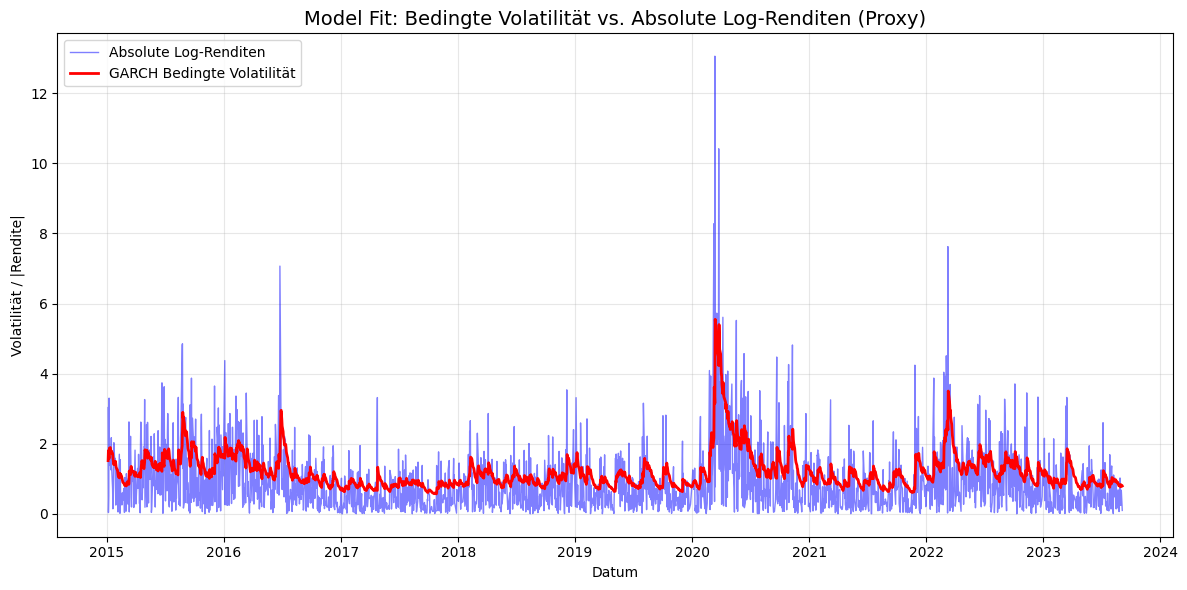

In [13]:
#Visualisierung des Fit auf training data: Bedingte Volatilität vs. Absolute Log-Renditen (Proxy)


# 1. Daten extrahieren
cond_vol = best_model_fit.conditional_volatility # Bedingte Volatilität (standardabweichung) des GARCH-Modells)
abs_returns = np.abs(train_df) # Absolute Log-Renditen als Proxy für Volatilität

# 2. Plot erstellen
plt.figure(figsize=(12, 6))

# Die absoluten Renditen im Hintergrund (grau und transparent)
plt.plot(abs_returns, color='blue', alpha=0.5, linewidth=1, label='Absolute Log-Renditen')

# Die vom GARCH geschätzte Volatilität darüber (rot und deutlich)
plt.plot(cond_vol, color='red', linewidth=2, label='GARCH Bedingte Volatilität')

# 3. Formatierung
plt.title('Model Fit: Bedingte Volatilität vs. Absolute Log-Renditen (Proxy)', fontsize=14)
plt.ylabel('Volatilität / |Rendite|')
plt.xlabel('Datum')
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

### 5.1.3. Residuenanalyse des GARCH-Modells

Die standardisierten Residuen stammen vom ausgewählten **Refit-Modell**, nicht vom zuletzt geschätzten Kandidaten der Rastersuche. Zeitverlauf, Histogramm und ACF dienen der diagnostischen Suche nach verbliebenen Mustern.

Unauffällige ACF-Grafiken beweisen weder vollständige Unabhängigkeit noch Modellkorrektheit. Ein formaler Ljung-Box-Test ist im vorliegenden Code optional auskommentiert; sein Ergebnis wird deshalb nicht behauptet.


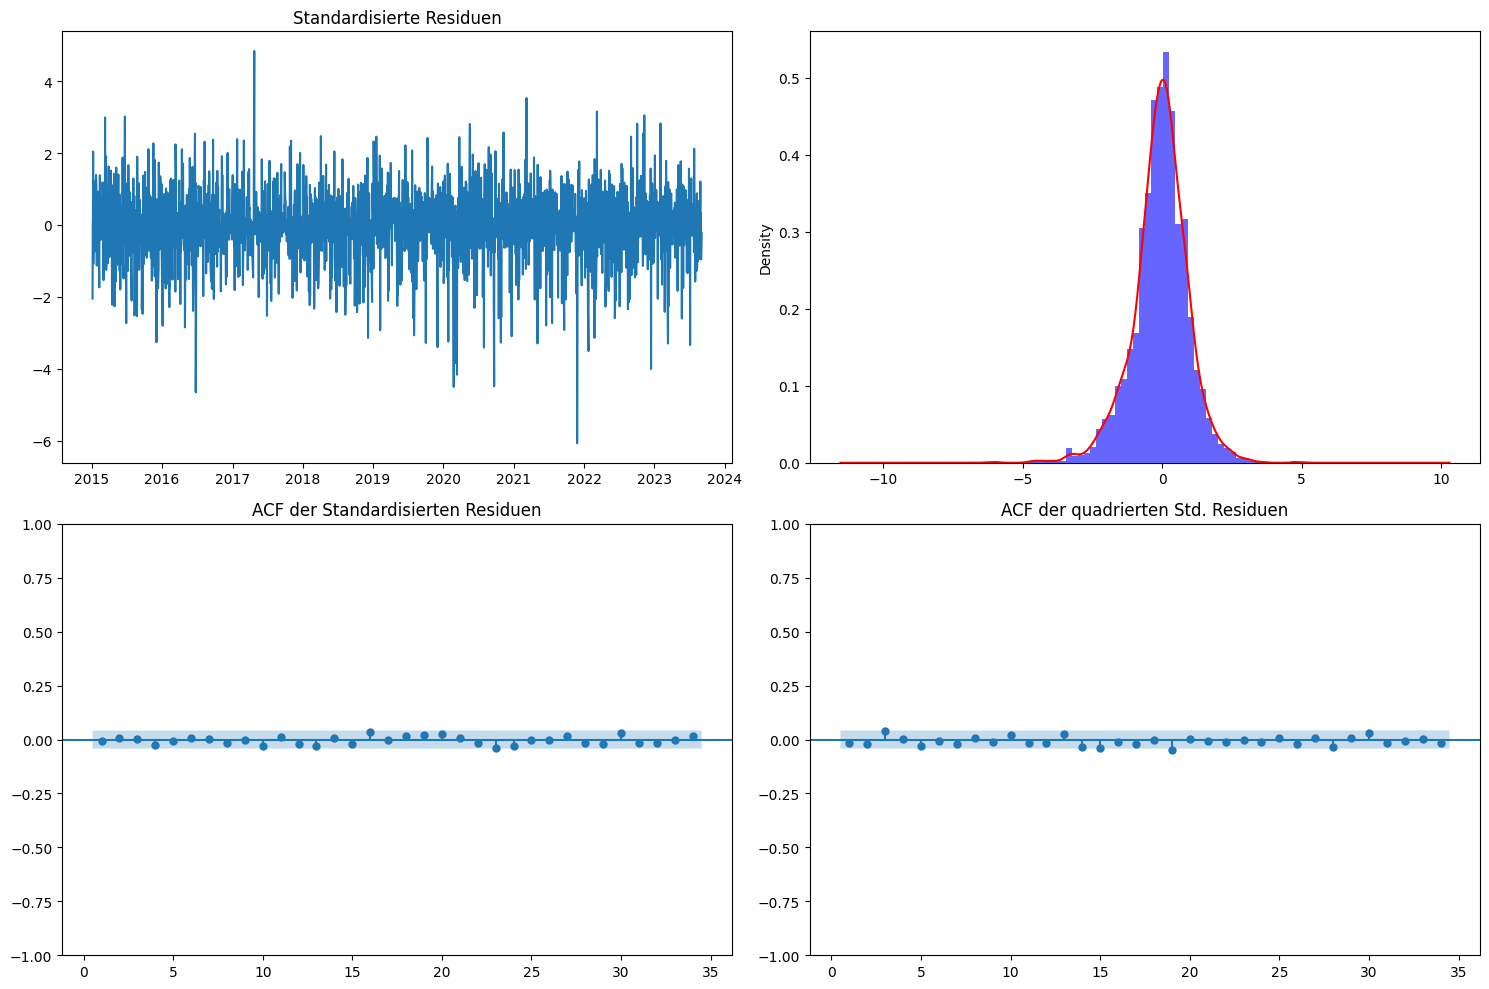

In [14]:
#Residuen-Analyse des besten Modells

# residuen extrahieren
std_resid = best_model_fit.std_resid

# Erstelle ein 2x2 Plot-Fenster
fig, ax = plt.subplots(2, 2, figsize=(15, 10))

# 1. Standardisierte Residuen über die Zeit (Weisses Rauschen im besten Fall)
ax[0, 0].plot(std_resid)
ax[0, 0].set_title('Standardisierte Residuen')

# 2. Histogramm & Dichte (Verteilung prüfen)
ax[0, 1].hist(std_resid, bins=50, density=True, alpha=0.6, color='blue')
std_resid.plot(kind='kde', ax=ax[0, 1], color='red')
#ax[0, 1].set_title('Histogramm vs. Dichte')

# 3. ACF der Standardisierten Residuen (Check auf Autokorrelation im Mittelwert)
plot_acf(std_resid, ax=ax[1, 0], zero=False)
ax[1, 0].set_title('ACF der Standardisierten Residuen')

# 4. ACF der QUADRIERTEN Standardisierten Residuen (Check auf ARCH-Effekte)
plot_acf(std_resid**2, ax=ax[1, 1], zero=False)
ax[1, 1].set_title('ACF der quadrierten Std. Residuen')

plt.tight_layout()
plt.show()

#Optional Ljung-Box Test der Residuen

#from statsmodels.stats.diagnostic import acorr_ljungbox

#ljung_box_test = acorr_ljungbox(std_resid, lags=10, return_df=True)
#ljung_box_test


### 5.1.4. GARCH Out-of-Sample Forecast

Die abschließende Prognose beginnt nach dem 80-%-Refit. Für jeden der 550 Bewertungstage wird die ausgewählte Spezifikation mit der bis zum Vortag verfügbaren Historie neu geschätzt und eine Ein-Schritt-Prognose erzeugt. Die Modellordnung bleibt über den gesamten Bewertungszeitraum unverändert.


In [15]:
# Abschliessende Bewertung: dieselbe Walk-Forward-Methode wie bei der Validierung.
# val_df ist der bestehende Variablenname fuer die letzten 20 %.
# Beobachtete Renditen gehen erst am folgenden Prognosetag in die Schaetzung ein.
# Die gewaehlten p/q werden im Bewertungszeitraum NICHT erneut ausgewaehlt.
print(f'Bewertungsprognosen gestartet: {garch_label}')
garch_evaluation_forecasts = garch_walk_forward(
    train_df, val_df, selected_p, selected_q, progress_every=50
)
forecast_series = garch_evaluation_forecasts['variance'].rename('GARCH forecast variance')
# Vorhalten fuer die spaetere, separate Korrektur der VaR-Berechnung.
garch_forecast_mean = garch_evaluation_forecasts['mean']
garch_forecast_nu = garch_evaluation_forecasts['nu']
forecasted_variance = forecast_series.tolist()
assert forecast_series.index.equals(val_df.index)
assert len(forecast_series) == len(val_df)
print('Bewertungsprognosen abgeschlossen.')


Bewertungsprognosen gestartet: GARCH(1,1)
GARCH(1,1): 1/550 Prognosen
GARCH(1,1): 51/550 Prognosen
GARCH(1,1): 101/550 Prognosen
GARCH(1,1): 151/550 Prognosen
GARCH(1,1): 201/550 Prognosen
GARCH(1,1): 251/550 Prognosen
GARCH(1,1): 301/550 Prognosen
GARCH(1,1): 351/550 Prognosen
GARCH(1,1): 401/550 Prognosen
GARCH(1,1): 451/550 Prognosen
GARCH(1,1): 501/550 Prognosen
GARCH(1,1): 550/550 Prognosen
Bewertungsprognosen abgeschlossen.


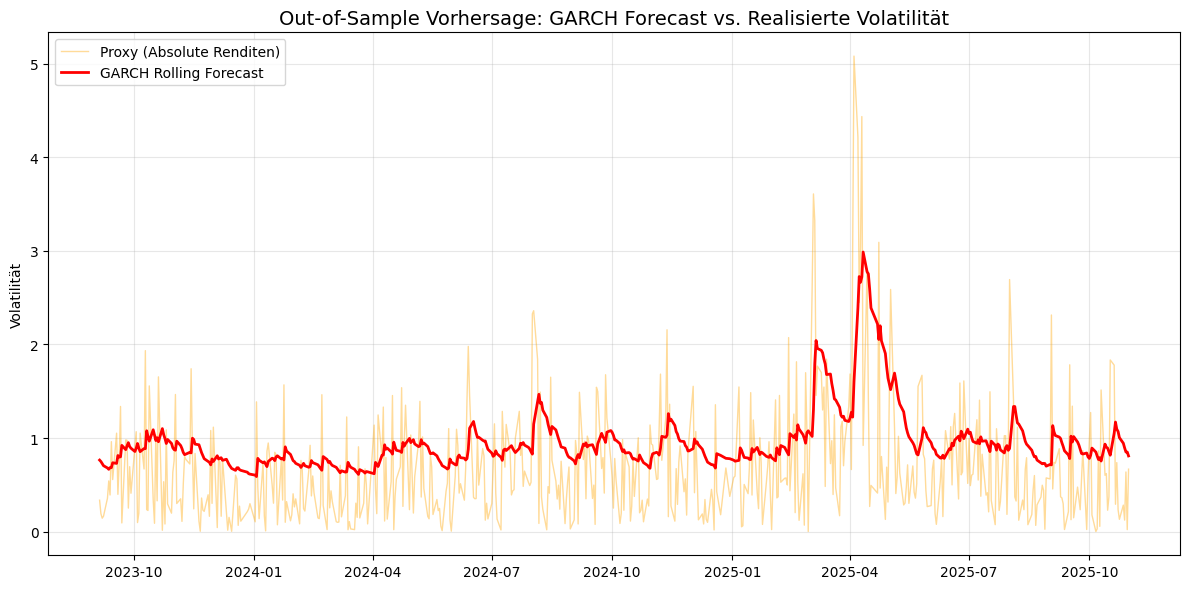

In [16]:
# Forecast vs. Realisierte Volatilität plotten

# 'forecast_series' enthält Varianzen.
# Für die voltatlität (sigma), Wurzelziehen.
predicted_volatility = np.sqrt(forecast_series)

# Der Proxy für die "wahre" Volatilität sind die absoluten Renditen aus dem abschliessenden Bewertungszeitraum
absolute_returns = np.abs(val_df)

#Plot erstellen
plt.figure(figsize=(12, 6))

# Der Proxy (Absolute Renditen) in orange im Hintergrund
plt.plot(absolute_returns.index, absolute_returns, 
         color='orange', alpha=0.4, linewidth=1, label='Proxy (Absolute Renditen)')

# Die GARCH Rolling Forecast Volatilität in Rot im Vordergrund
plt.plot(predicted_volatility.index, predicted_volatility, 
         color='red', linewidth=2, label='GARCH Rolling Forecast')

plt.title('Out-of-Sample Vorhersage: GARCH Forecast vs. Realisierte Volatilität', fontsize=14)
plt.ylabel('Volatilität')
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

Die Gesamtgrafik trennt die ersten 80 % als Refit-Daten von den letzten 20 % als Bewertungszeitraum. Die zusätzliche Markierung bei 70 % zeigt die frühere Grenze zur Auswahlvalidierung.


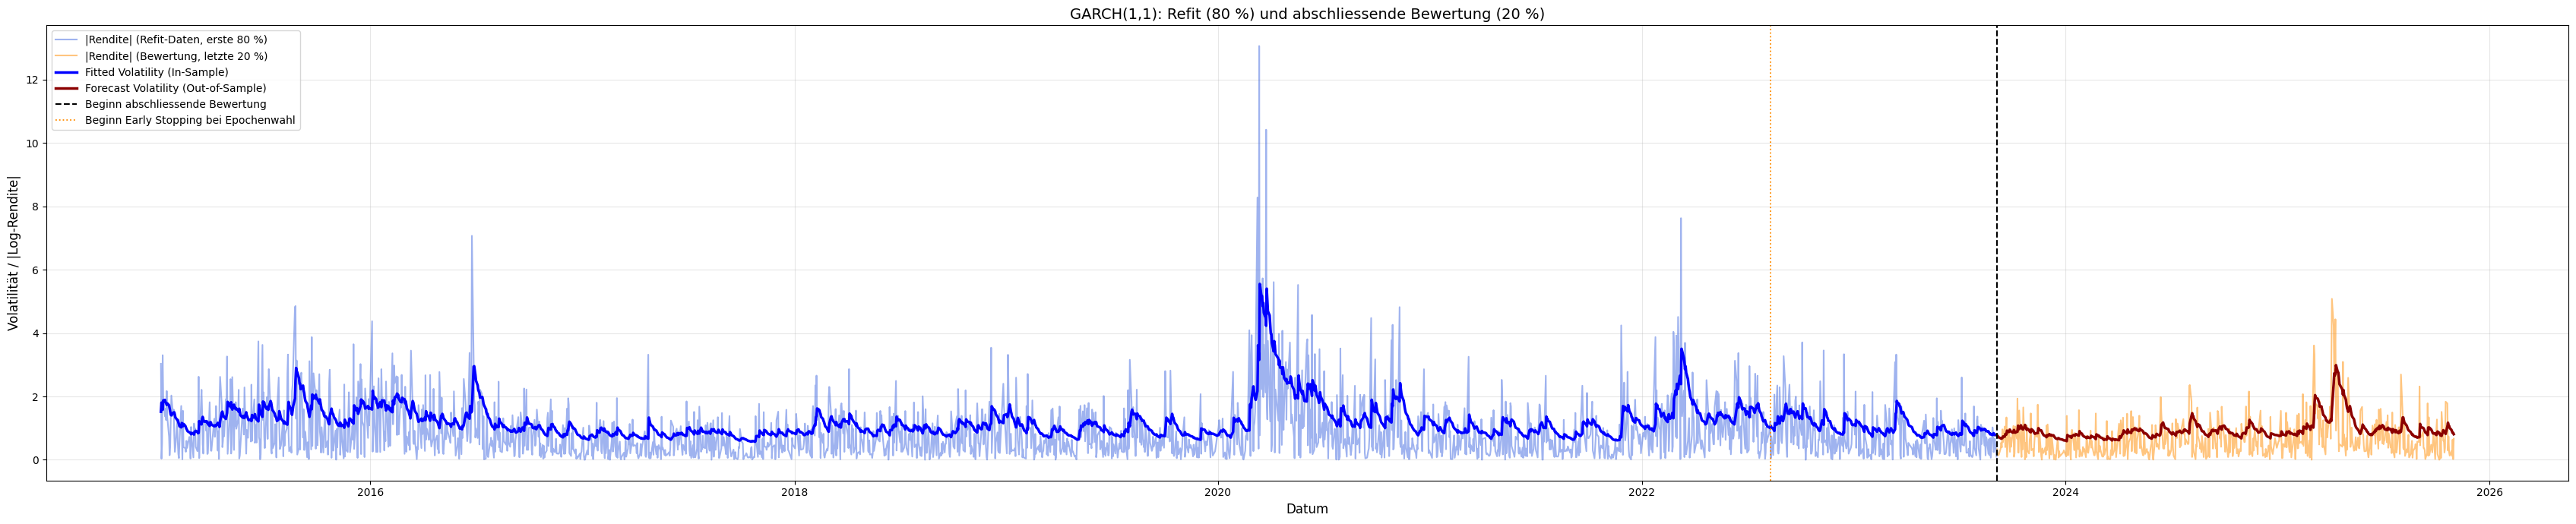

In [17]:
#Gesamte Visualisierung: Training vs. Validation inkl. Fitted & Forecast Volatilität

# 1. Absolutbeträge der Renditen (Proxy für Volatilität)
abs_train = np.abs(train_df)
abs_val = np.abs(val_df)

# 2. Fitted Values (Volatilität im Training)
# 'best_model.conditional_volatility' enthält bereits die Sigma-Werte (keine Varianz), 
# daher wird hier keine Wurzel gezogen.
fitted_vol = best_model_fit.conditional_volatility

# 3. Forecast Values (Volatilität in der Validation)
# 'forecast_series' enthielt die VARIANZ und nicht die Volatilität. Daher müssen wir hier die Wurzel ziehen.
forecast_vol = np.sqrt(forecast_series)

# --- PLOTTING ---

plt.figure(figsize=(34, 7))

# A) HINTERGRUND: Die "Realität" (Absolute Renditen)
# Wir machen sie transparent (alpha=0.3), damit man die Modell-Linien gut sieht.
plt.plot(abs_train.index, abs_train, color='royalblue', alpha=0.5, label='|Rendite| (Refit-Daten, erste 80 %)')
plt.plot(abs_val.index, abs_val, color='darkorange', alpha=0.5, label='|Rendite| (Bewertung, letzte 20 %)')

# B) VORDERGRUND: Das Modell (Fitted & Forecast)
plt.plot(fitted_vol.index, fitted_vol, color='blue', linewidth=2.5, label='Fitted Volatility (In-Sample)')
plt.plot(forecast_vol.index, forecast_vol, color='darkred', linewidth=2.5, label='Forecast Volatility (Out-of-Sample)')

# C) TRENNLINIE (Split Point)
# Wir nehmen den ersten Tag der Validation als Trennlinie
split_date = val_df.index[0]
plt.axvline(split_date, color='black', linestyle='--', linewidth=1.5, label='Beginn abschliessende Bewertung')

# D) FORMATIERUNG
plt.title(f'{garch_label}: Refit (80 %) und abschliessende Bewertung (20 %)', fontsize=14)
plt.ylabel('Volatilität / |Log-Rendite|', fontsize=12)
plt.xlabel('Datum', fontsize=12)
plt.legend(loc='upper left', frameon=True)
plt.grid(True, alpha=0.3)

plt.axvline(early_stop_df.index[0], color='darkorange', linestyle=':', linewidth=1.3, label='Beginn Early Stopping bei Epochenwahl')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

Die GARCH-Linie zeigt eine prognostizierte bedingte Standardabweichung; die absoluten Renditen im Hintergrund sind einzelne Realisationen. Eine glattere Prognoselinie und Abweichungen von einzelnen Ausschlägen sind deshalb nicht automatisch Fehler des Modells. Ob die prognostizierten Verlustschwellen passend kalibriert sind, wird separat mit dem VaR geprüft.


### 5.1.5. MAE und RMSE Berechnung für GARCH

MAE und RMSE werden auf denselben 550 Bewertungstagen berechnet. Beide beziehen sich hier auf den Abstand zur absoluten Rendite und werden nach Rücktransformation in **Prozentpunkten** angegeben.


In [18]:
##MAE und RMSE Berechnung für GARCH Modell
# MAE berechnen
garch_mae = mean_absolute_error(abs_val, predicted_volatility)
# RMSE berechnen
garch_rmse = np.sqrt(mean_squared_error(abs_val, predicted_volatility))

print(f"GARCH Modell - MAE: {garch_mae:.6f}, RMSE: {garch_rmse:.6f}")

GARCH Modell - MAE: 0.525256, RMSE: 0.650447


Die Ausgabe enthält die aktuellen Werte nach Datenbereinigung und Neuschätzung. Der RMSE gewichtet größere Fehler stärker als der MAE. Ein höherer RMSE beweist allein weder eine Unterschätzung extremer Bewegungen noch eine fehlerhafte VaR-Abdeckung; Richtung und Risikokalibrierung müssen gesondert untersucht werden.


## 5.2. Ergebnisse des LSTM-Netzes

### 5.2.1. LSTM Spezfikationen

Das LSTM erhält absolute Renditen als Ziel- und Eingangsgröße. Die erste Phase passt den Min-Max-Skalierer ausschließlich an die ersten 70 % an. Der folgende 10-%-Abschnitt wird mit denselben Parametern transformiert.

Ein Fenster von 120 vergangenen Tagen prognostiziert die absolute Rendite des nächsten Tages. Für den ersten Validierungstag kommen die 120 Eingangswerte aus der davorliegenden Trainingshistorie. Die Fenster enthalten keine zukünftigen Renditen. Die gewählte Fensterlänge ist eine feste Projektkonfiguration; ihre Optimalität wurde nicht nachgewiesen.


In [19]:
#Seed setzen für Reproduzierbarkeit
import os
import random
def set_seeds(seed=420):
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

set_seeds(420)


# Select the number of epochs without consulting final-evaluation observations.
window_size = 120

def create_sequences(data, window):
    X, y = [], []
    for i in range(window, len(data)):
        X.append(data[i-window:i])
        y.append(data[i])
    return np.asarray(X), np.asarray(y)

train_abs = np.abs(train_df)
val_abs = np.abs(val_df)
scaler = MinMaxScaler(feature_range=(0, 1))
selection_scaled = scaler.fit_transform(np.abs(fit_df).values.reshape(-1, 1))
early_scaled = scaler.transform(np.abs(early_stop_df).values.reshape(-1, 1))
X_train, y_train = create_sequences(selection_scaled, window_size)
# Use the preceding training history for every validation target, including the first.
early_pool = np.concatenate([selection_scaled[-window_size:], early_scaled])
X_val, y_val = create_sequences(early_pool, window_size)
assert len(X_val) == len(early_stop_df)


Die Architektur umfasst 25 LSTM-Einheiten und eine lineare Ausgabeeinheit. Adam optimiert den skalierten MSE. Dropout ist auf null gesetzt; daraus folgt keine automatische Vermeidung von Overfitting. Eine umfassende Hyperparametersuche wird für dieses Portfolio-Projekt nicht durchgeführt.


In [20]:
#LSTM Modell erstellen

# Modell initialisieren
model = Sequential()

# 1. LSTM Layer
# Nach Fischer & Kraus (2017) sind 25 Neuronen oft ausreichend.
# Bei Finanzdaten bringen hunderte Neuronen oft keinen Mehrwert, nur Overfitting.
# input_shape muss (Time Steps, Features) sein -> (window_size, 1)
model.add(LSTM(units=25, input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=False))

# 2. Dropout Layer 
# auf 0.0 gesetzt, da die Datenmenge für LSTMs eher klein ist.
# Dropout kann bei kleinen Datenmengen das Lernen erschweren.
model.add(Dropout(0.0))

# 3. Output Layer
# Wir wollen genau einen Wert vorhersagen (die Volatilität von morgen)
# Activation auf 'linear'.
# Da wir 0-1 skaliert haben, könnte man auch 'relu' oder 'sigmoid' testen, 
# aber 'linear' ist die sicherste Wahl, um nichts abzuschneiden.
model.add(Dense(1, activation='linear')) 

# 4. Kompilieren
# Der Adam Optimizer ist Standard. 
# Eine Lernrate von 0.001 wird genommen,da sie ein guter Kompromiss zwischen Konvergenzgeschwindigkeit und Stabilität ist.
optimizer = Adam(learning_rate=0.001)

# Loss Function: MSE (Mean Squared Error) ist Standard für das Training, 
# auch wenn später mit RMSE und MAE evaluiert wird. MSE bestraft große Abweichungen stärker.
model.compile(optimizer=optimizer, loss='mse')

# 5. Early Stopping 
# Stoppt das Training, wenn der Validation Loss nicht mehr sinkt.
# Das verhindert, dass das Modell "zu lange" lernt und anfängt zu overfitten.
early_stop = EarlyStopping(
    monitor='val_loss', 
    patience=10,          # Warte 10 Epochen, ob es noch besser wird
    restore_best_weights=True # Setzt das Modell auf den besten Stand zurück
)

# Modellzusammenfassung anzeigen
model.summary()

/Users/marc/Library/Python/3.9/lib/python/site-packages/keras/src/layers/rnn/rnn.py:199:UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 25)             │         2,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 25)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,726 (10.65 KB)

 Trainable params: 2,726 (10.65 KB)

 Non-trainable params: 0 (0.00 B)

### 5.2.2. LSTM Fitting 

Das Training erfolgt in zwei Phasen:

1. **Epochenwahl:** Training auf 70 %, Validierungs-MSE auf den folgenden 10 %, Early Stopping nach zehn Epochen ohne Verbesserung.
2. **Finales Refit:** Neues Netz mit neu initialisierten Gewichten; Training auf den ersten 80 % für genau die ausgewählte Epochenzahl. Der Skalierer wird dafür auf diesen 80 % neu angepasst.

Der letzte 20-%-Abschnitt wird weder zur Epochenwahl noch als Validierung beim Refit verwendet. Gesetzte Seeds unterstützen die Reproduzierbarkeit, garantieren aber keine identischen Ergebnisse über Hardware- und Bibliotheksversionen hinweg.


In [21]:
# Stage 1: choose training duration on the small chronological validation period.
history = model.fit(
    X_train, y_train, epochs=1000, batch_size=25,
    validation_data=(X_val, y_val), callbacks=[early_stop], verbose=1,
    shuffle=False,
)
best_epochs = int(np.argmin(history.history['val_loss'])) + 1
print(f'Selected epochs: {best_epochs}')

# Stage 2: refit from scratch on all development data (first 80%).
# No early stopping or model selection uses the final 20%.
set_seeds(420)
scaler = MinMaxScaler(feature_range=(0, 1))
train_scaled = scaler.fit_transform(train_abs.values.reshape(-1, 1))
val_scaled = scaler.transform(val_abs.values.reshape(-1, 1))
X_train, y_train = create_sequences(train_scaled, window_size)
model = tf.keras.models.clone_model(model)
model.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
refit_history = model.fit(
    X_train, y_train, epochs=best_epochs, batch_size=25,
    shuffle=False, verbose=1,
)


Epoch 1/1000
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0065 - val_loss: 0.0027
Epoch 2/1000
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0046 - val_loss: 0.0026
Epoch 3/1000
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0046 - val_loss: 0.0026
Epoch 4/1000
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0046 - val_loss: 0.0027
Epoch 5/1000
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0046 - val_loss: 0.0027
Epoch 6/1000
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0046 - val_loss: 0.0027
Epoch 7/1000
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0046 - val_loss: 0.0027
Epoch 8/1000
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0046 - val_loss: 0.0027
Epoch 9/1000
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0046 - val_loss: 0.0027
Epoch 10/1000
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0046 - val_loss: 0.0027
Epoch 11/1000
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0046 - val_loss: 0.0027
Epoch 12/1000
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step

Die folgende Lernkurve zeigt ausschließlich die **erste Phase der Epochenwahl** mit Training (70 %) und Early Stopping (10 %). Sie zeigt nicht den zweiten Trainingslauf auf den gesamten 80 %.


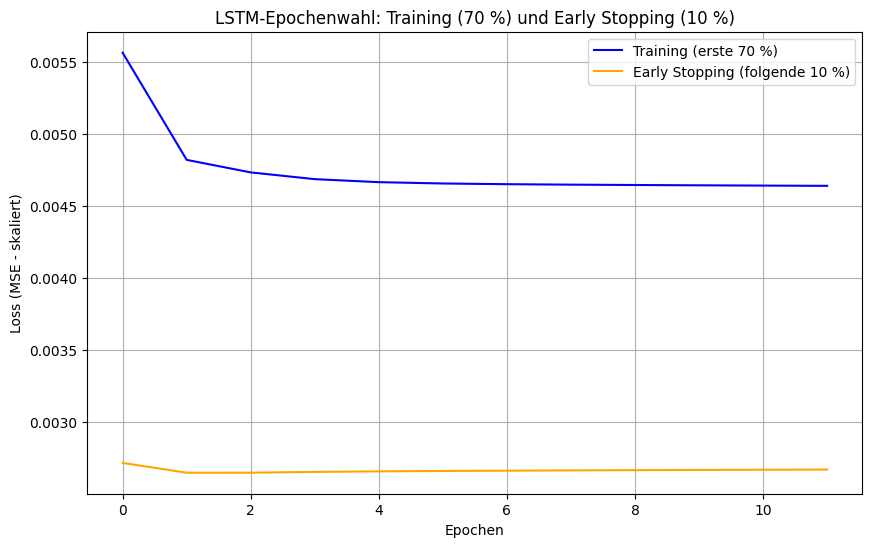

In [22]:
#Plot der Lernkurven
def plot_learning_curves(history):
    """
    Plottet den Trainings- und Validierungs-Loss über die Epochen.
    """
    plt.figure(figsize=(10, 6))
    
    # Trainings-Loss
    plt.plot(history.history['loss'], label='Training (erste 70 %)', color='blue')
    
    # Validierungs-Loss
    plt.plot(history.history['val_loss'], label='Early Stopping (folgende 10 %)', color='orange')
    
    plt.title('LSTM-Epochenwahl: Training (70 %) und Early Stopping (10 %)')
    plt.xlabel('Epochen')
    plt.ylabel('Loss (MSE - skaliert)')
    plt.legend()
    plt.grid(True)
    plt.show()

# Aufruf der Funktion nach dem Training
plot_learning_curves(history)

Im dokumentierten Lauf sinkt der Trainings-MSE zunächst und flacht anschließend ab. Der Validierungs-MSE liegt darunter und verbessert sich nach den ersten Epochen kaum noch.

Der Abstand ist mit der geringeren Streuung der Zielwerte im Validierungszeitraum vereinbar. Starke Trainingsausschläge erhöhen den quadratischen Fehler. Ein niedrigerer Validierungsfehler ist daher kein Widerspruch. Die frühe Abflachung allein beweist weder Underfitting noch Datenmangel oder erfolgreich gelernte komplexe Strukturen.


In [23]:
# Unterschiedliche Marktregime in den drei Zeitabschnitten.
for label, series in [('Training (70 %)', fit_df), ('Early Stopping (10 %)', early_stop_df), ('Bewertung (20 %)', val_df)]:
    print(f'{label}: durchschnittliche absolute Rendite = {np.abs(series).mean():.6f}')


Training (70 %): durchschnittliche absolute Rendite = 0.889564
Early Stopping (10 %): durchschnittliche absolute Rendite = 0.742154
Bewertung (20 %): durchschnittliche absolute Rendite = 0.681506


Die folgende Ausgabe vergleicht die mittleren absoluten Renditen der drei Abschnitte. Diese beschreiben unterschiedliche Schwankungsniveaus, ersetzen aber keine Analyse der Streuung oder der Beiträge einzelner Extremtage zum MSE.


Die nächste Grafik zeigt die **In-Sample-Prognosen des finalen LSTM-Refits auf den ersten 80 %**.


65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


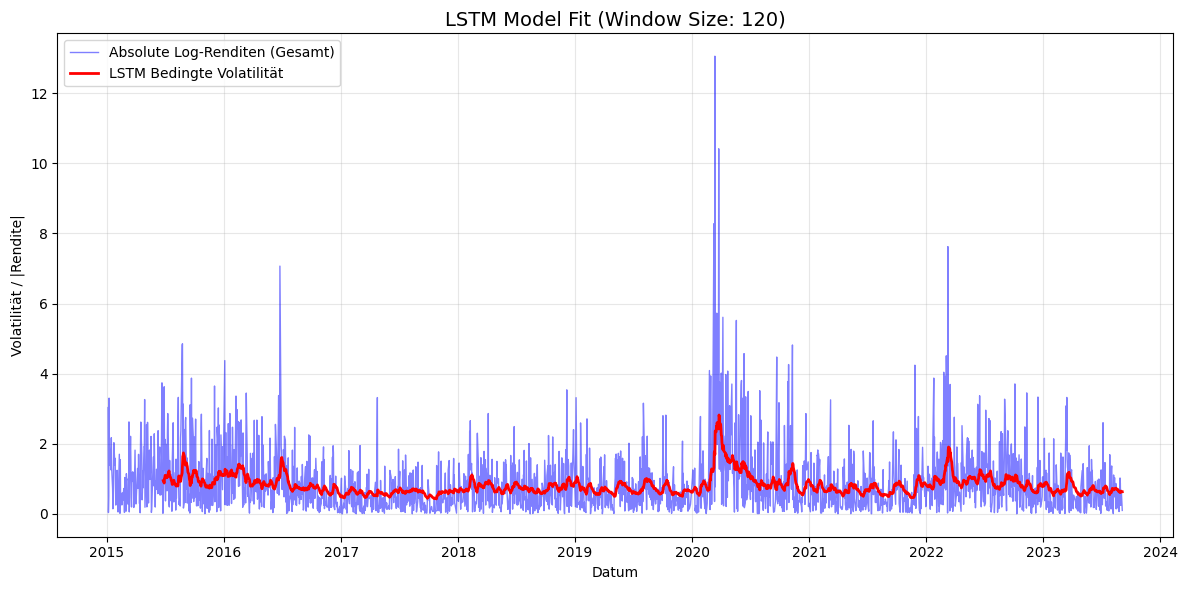

In [24]:
#LSTM fit auf Trainingsdaten visualisieren

# 1. Daten extrahieren & Längenabgleich
lstm_train_predictions = model.predict(X_train)
lstm_train_predictions_rescaled = scaler.inverse_transform(lstm_train_predictions).flatten()

# Wir erstellen eine Pandas Series, die die volle Länge der Trainingsdaten hat.
# Wir füllen sie erst mit NaNs, um den "blinden Fleck" (ersten 120 Tage) des LSTMs zu simulieren.
full_train_index = train_df.index 
cond_vol_aligned = pd.Series(np.nan, index=full_train_index)

# Wir füllen den Bereich AB window_size mit den Vorhersagen
# Sicherheitshalber prüfen wir, ob die Längen matchen
expected_len = len(full_train_index) - window_size
if len(lstm_train_predictions_rescaled) == expected_len:
    cond_vol_aligned.iloc[window_size:] = lstm_train_predictions_rescaled
else:
    print(f"Dimension Mismatch! Preds: {len(lstm_train_predictions_rescaled)}, Slot: {expected_len}")

# Auch die absoluten Renditen nehmen wir komplett (zum Vergleich)
abs_returns_full = np.abs(train_df) 
# --- KORREKTUR ENDE ---

# 2. Plot erstellen
plt.figure(figsize=(12, 6)) 

# Plotten der GESAMTEN Zeitreihe der Renditen (auch die ersten 120 Tage)
plt.plot(abs_returns_full.index, abs_returns_full, color='blue', alpha=0.5, linewidth=1, label='Absolute Log-Renditen (Gesamt)')

# Plotten der LSTM Volatilität (Die ersten 120 Tage bleiben leer/unsichtbar)
plt.plot(cond_vol_aligned.index, cond_vol_aligned, color='red', linewidth=2, label='LSTM Bedingte Volatilität')

# 3. Formatierung
plt.title(f'LSTM Model Fit (Window Size: {window_size})', fontsize=14)
plt.ylabel('Volatilität / |Rendite|')
plt.xlabel('Datum')
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)


plt.tight_layout()
plt.show()

Die ersten 120 Tage besitzen keine LSTM-Prognose, da für sie das vollständige Eingabefenster fehlt. Der gezeigte Fit stammt aus den zur finalen Schätzung verwendeten Daten und belegt daher keine Generalisierung oder Robustheit. Seine Aufgabe ist die visuelle Diagnose von Niveau, Streuung und offensichtlichen Auffälligkeiten.


### 5.2.3. LSTM Out-of-Sample Forecast

Die folgenden Prognosen beziehen sich auf die letzten 550 Tage. Das Eingabefenster wird täglich aktualisiert, die Gewichte des finalen LSTM bleiben unverändert.


Starte rollierende Prognose für LSTM.
Prognostiziert: Tag 0 von 550
Prognostiziert: Tag 100 von 550
Prognostiziert: Tag 200 von 550
Prognostiziert: Tag 300 von 550
Prognostiziert: Tag 400 von 550
Prognostiziert: Tag 500 von 550
Rolling Forecast abgeschlossen.


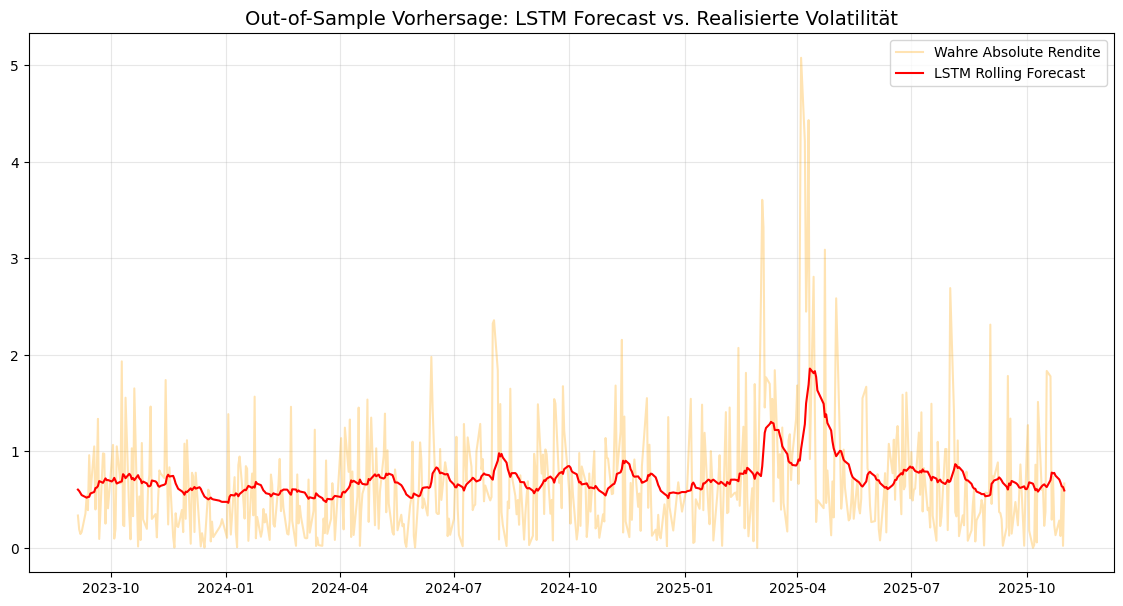

In [25]:
#Rolling Forecast mit LSTM (Walk-Forward)

# Annahme:
# model = Das fertig trainierte LSTM 
# scaler = Der gefittete MinMaxScaler
# val_scaled = Die skalierten Daten des abschliessenden Bewertungszeitraums 
# val_df = Das originale DataFrame der abschliessenden Bewertungsphase (für Indizes)
# window_size = 120 (wie oben definiert) 

# 1. Vorbereitung der "Rolling Inputs"
# Damit der erste Tag im abschliessenden Bewertungszeitraum vorhergesagt werden kann, braucht man
# die letzten 'window_size' Tage aus dem TRAINING-Set als Start-Input.
# --> die letzten 120 Tage vom Training und hängt das Val-Set dran.

# Letzte 'window_size' Datenpunkte vom Training holen
last_train_data = train_scaled[-window_size:]

# Zusammenfügen: Das ist unser "Pool", durch den wir rollen
rolling_data = np.concatenate((last_train_data, val_scaled), axis=0)

# 2. Walk-Forward Loop
forecasts_scaled = []

print("Starte rollierende Prognose für LSTM.")

# Durch jeden Tag im abschliessenden Bewertungszeitraum iterieren
# Wir starten bei Index 'window_size', da wir 120 Tage Historie brauchen
for i in range(window_size, len(rolling_data)):
    
    # a) Das Fenster definieren (die letzten 120 Tage vor dem aktuellen Tag i)
    # Shape muss sein: (1, window_size, 1) für Keras
    current_window = rolling_data[i-window_size:i]
    current_window = current_window.reshape((1, window_size, 1))
    
    # b) Vorhersage machen (für Tag i)
    # verbose=0 macht es schneller (kein Output pro Schritt)
    pred = model.predict(current_window, verbose=0)
    
    # c) Speichern
    forecasts_scaled.append(pred[0, 0])

    # Fortschrittsanzeige alle 100 Tage
    if (i - window_size) % 100 == 0:
        print(f"Prognostiziert: Tag {i-window_size} von {len(val_scaled)}")

# 3. Rücktransformation (Inverse Scaling)
forecasts_scaled = np.array(forecasts_scaled).reshape(-1, 1)
lstm_forecast_volatility = scaler.inverse_transform(forecasts_scaled)

# 4. Erstellen einer sauberen Pandas Series für den Plot
# Den Index von val_df, damit es perfekt zum GARCH passt
lstm_forecast_series = pd.Series(lstm_forecast_volatility.flatten(), index=val_df.index)

print("Rolling Forecast abgeschlossen.")

# Forecast plotten
plt.figure(figsize=(14, 7))

# Wahre Volatilität (Proxy)
plt.plot(val_df.index, np.abs(val_df), color='orange', alpha=0.3, label='Wahre Absolute Rendite')

# LSTM Prognose
plt.plot(lstm_forecast_series.index, lstm_forecast_series, color='red', linewidth=1.5, label='LSTM Rolling Forecast')

plt.title('Out-of-Sample Vorhersage: LSTM Forecast vs. Realisierte Volatilität', fontsize=14)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()



Die Grafik erlaubt eine deskriptive Betrachtung der zeitlichen Anpassung. Eine Reaktion nach einem starken Ausschlag ist von dessen Vorhersage zu unterscheiden. Visuelle Ähnlichkeit allein belegt weder Antizipation von Marktwechseln noch strukturelle Stabilität.

Die Gesamtansicht trennt anschließend Refit und abschließende Bewertung.


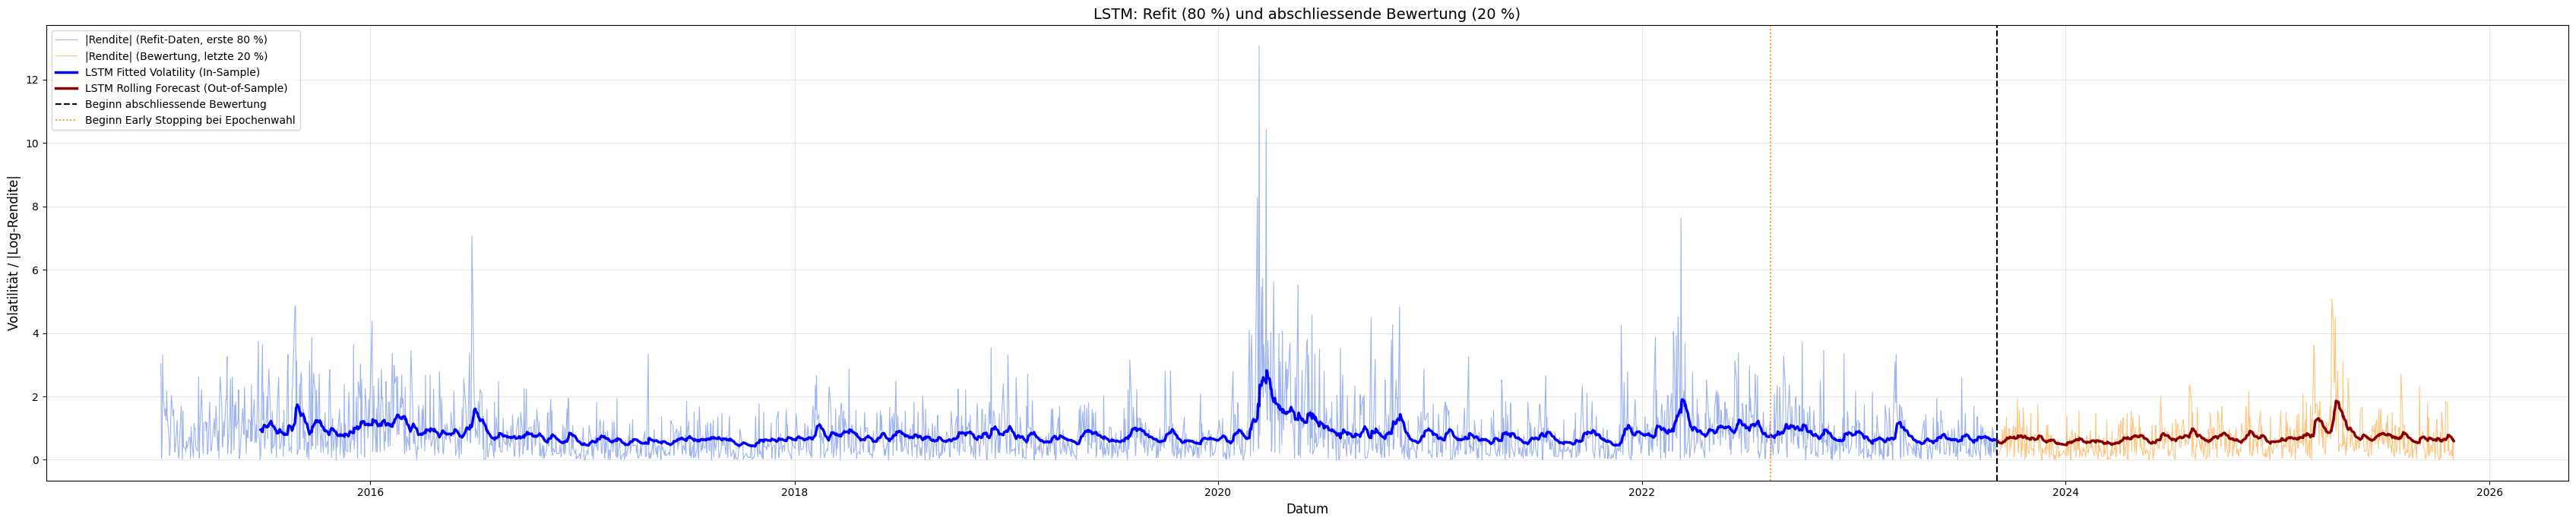

In [26]:
#Gesamte Visualisierung: Training vs. Validation inkl. Fitted & Forecast Volatilität

# Voraussetzungen wie eben

#In-Sample Vorhersagen generieren ("Fitted Values") 

# Wir lassen das Modell auf den Daten vorhersagen, auf denen es trainiert wurde
train_pred_scaled = model.predict(X_train, verbose=0)

# Rücktransformation in den originalen Wertebereich
train_pred_inverse = scaler.inverse_transform(train_pred_scaled)

# WICHTIG: Zurechtschneiden des Index
# Da wir ein Sliding Window nutzen, haben wir für die ersten 'window_size' Tage
# keine Vorhersage. Der Index von X_train beginnt also erst ab window_size.
window_size = X_train.shape[1] # Sollte 21 sein
train_pred_index = train_df.index[window_size:]

# Erstellen einer sauberen Pandas Series für den Plot
fitted_volatility = pd.Series(train_pred_inverse.flatten(), index=train_pred_index)


# Plot erstellen
plt.figure(figsize=(34, 7))

# A) Hintergrund: Die wahren absoluten Renditen (Proxy)
# Trainings-Teil (Hellblau)
plt.plot(train_df.index, np.abs(train_df), color='royalblue', alpha=0.5, linewidth=0.8, label='|Rendite| (Refit-Daten, erste 80 %)')
# Validierungs-Teil (Hellorange)
plt.plot(val_df.index, np.abs(val_df), color='darkorange', alpha=0.5, linewidth=0.8, label='|Rendite| (Bewertung, letzte 20 %)')

# B) Das Modell: Fitted Values & Forecast
# In-Sample Fit (Dunkelblau) - Wie im GARCH Plot
plt.plot(fitted_volatility.index, fitted_volatility, color='blue', linewidth=2.5, label='LSTM Fitted Volatility (In-Sample)')

# Out-of-Sample Forecast (Dunkelrot) - Wie im GARCH Plot
# Wir nutzen hier deine bereits erstellte 'lstm_forecast_series'
plt.plot(lstm_forecast_series.index, lstm_forecast_series, color='darkred', linewidth=2.5, label='LSTM Rolling Forecast (Out-of-Sample)')

# C) Die Trennlinie (Split Point)
split_date = val_df.index[0]
plt.axvline(x=split_date, color='black', linestyle='--', linewidth=1.5, label='Beginn abschliessende Bewertung')

# D) Formatierung
plt.title('LSTM: Refit (80 %) und abschliessende Bewertung (20 %)', fontsize=14)
plt.ylabel('Volatilität / |Log-Rendite|', fontsize=12)
plt.xlabel('Datum', fontsize=12)
plt.legend(loc='upper left', frameon=True, shadow=True)
plt.grid(True, alpha=0.3)

plt.axvline(early_stop_df.index[0], color='darkorange', linestyle=':', linewidth=1.3, label='Beginn Early Stopping bei Epochenwahl')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

#'royalblue'

### 5.2.4. MAE und RMSE für LSTM und Vergleich beider Modelle 

Die folgende Ausgabe enthält die aktuellen MAE- und RMSE-Werte der LSTM-Prognosen für den abschließenden Bewertungszeitraum.


In [27]:
#MAE und RMSE Berechnung für LSTM Modell

# MAE berechnen
lstm_mae = mean_absolute_error(val_abs, lstm_forecast_series)
# RMSE berechnen
lstm_rmse = np.sqrt(mean_squared_error(val_abs, lstm_forecast_series))

print(f"LSTM Modell - MAE: {lstm_mae:.6f}, RMSE: {lstm_rmse:.6f}")

LSTM Modell - MAE: 0.442522, RMSE: 0.596926


Die beiden Fehlermaße werden für denselben Zeitraum gegenübergestellt. Wegen der unterschiedlichen Zielgrößen — absolute Rendite beim LSTM, Standardabweichung bei GARCH — bleibt die Interpretation auf den beschriebenen Proxy-Vergleich beschränkt.


In [28]:
#Resultate vergleichen und Fazit ziehen
print(f"GARCH Modell - MAE: {garch_mae:.6f}, RMSE: {garch_rmse:.6f}")
print(f"LSTM Netz - MAE: {lstm_mae:.6f}, RMSE: {lstm_rmse:.6f}")

GARCH Modell - MAE: 0.525256, RMSE: 0.650447
LSTM Netz - MAE: 0.442522, RMSE: 0.596926


Ein niedrigerer Tabellenwert bedeutet einen kleineren beobachteten Fehler gegenüber absoluten Renditen. Es wurde kein formaler Test der Differenz der Prognosefehler durchgeführt. Deshalb werden weder statistische Signifikanz noch eine allgemeine Überlegenheit behauptet.

Die neuen MAE-/RMSE-Werte werden unmittelbar vom Code ausgegeben; alte Zahlen der ursprünglichen Seminarfassung sind nicht auf die bereinigte Analyse übertragbar. H1 ist anhand dieses explorativen Vergleichs in seiner Aussagekraft begrenzt.


## 5.3. VaR Backtesting Analyse 

### Vom Modell zur Renditeschwelle

**GARCH:** Für jeden Prognosetag werden dessen Mittelwert $\hat\mu_t$, Standardabweichung $\hat\sigma_t$ und Freiheitsgrade $\hat\nu_t$ verwendet. Da `arch` Student-t-Innovationen auf Varianz eins standardisiert, lautet die untere Renditeschwelle:

$$q^G_{t,\alpha}=\hat\mu_t+\hat\sigma_t\sqrt{\frac{\hat\nu_t-2}{\hat\nu_t}}\;t^{-1}_{\hat\nu_t}(\alpha),\qquad\alpha=0.05.$$

Der Skalierungsfaktor unterscheidet die standardisierte Verteilung vom gewöhnlichen `scipy.stats.t`-Quantil. Ein fester Freiheitsgrad aus dem initialen Refit wird nicht mehr für alle Tage verwendet.

**LSTM:** Die prognostizierte absolute Rendite $\hat a_t$ wird als positive Skala verwendet, nicht als GARCH-Standardabweichung bezeichnet. Auf den ersten 80 % werden anhand der In-Sample-Prognosen Quotienten $z_t=r_t/\hat a_t$ gebildet. Eine Student-t-Verteilung wird an diese Quotienten angepasst, einschließlich Lage $\ell$ und Skala $s$:

$$q^L_{t,\alpha}=\hat a_t\left[\hat\ell+\hat s\;t^{-1}_{\hat\nu_L}(\alpha)\right].$$

Die Kalibrierungsparameter bleiben während der Bewertung fest. Der letzte 20-%-Abschnitt geht nicht in ihre Schätzung ein. Die Verwendung von In-Sample-Quotienten ist jedoch eine verbleibende Einschränkung. Das LSTM allein erzeugt hier keine probabilistische Renditeprognose; diese entsteht erst durch die zusätzliche t-Kalibrierung.

Beide Modelle werden auf exakt denselben 550 Tagen geprüft. Fehlende Werte, fehlerhafte Zeitindizes oder nichtpositive LSTM-Skalen führen zu einer expliziten Fehlermeldung statt zu einer stillen Verkürzung der Stichprobe.


Die t-Faktoren beziehen sich auf unterschiedliche Skalen und sind nicht direkt vergleichbar.
LSTM-Kalibrierung: nu=4.3822, loc=0.0776, scale=1.0626


,GARCH (standardisierte t),LSTM (t-kalibrierte Skala)
Beobachtungen,550.000000,550.000000
Freiheitsgrade nu (Median),4.951181,4.382242
Unteres t-Quantil (Median),-1.559106,-2.132107
Breaches,32.000000,25.000000
Ueberschreitungsquote,0.058182,0.045455
Erwartete Quote,0.050000,0.050000


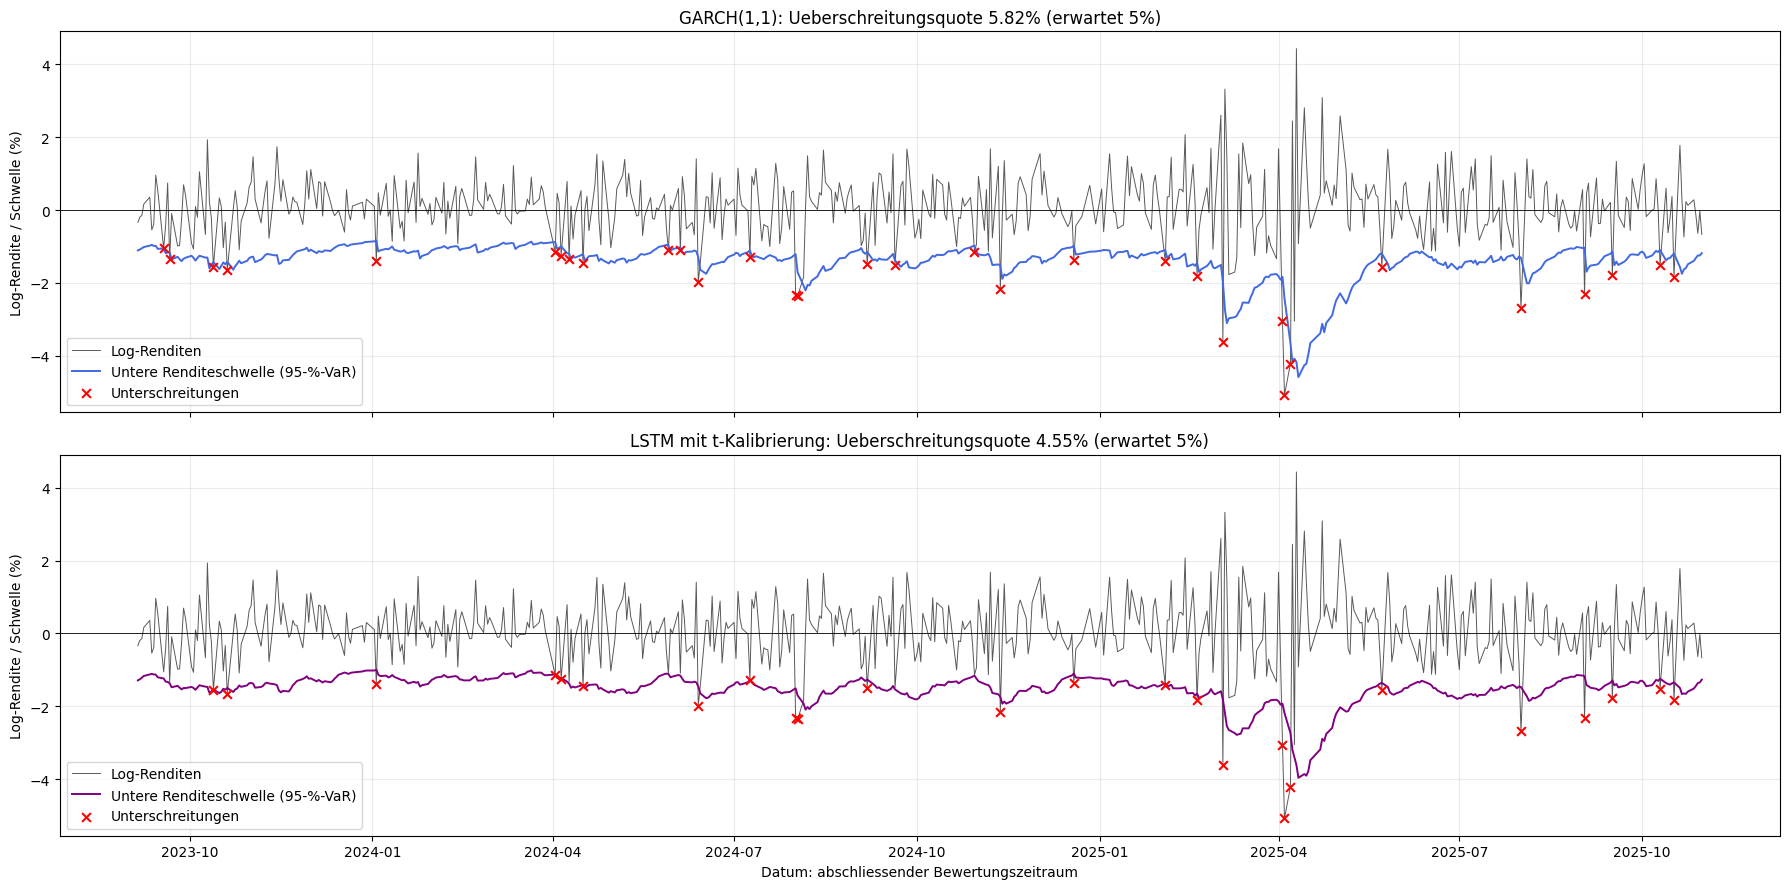

In [29]:
# Ein-Tages-VaR bei 95 %: unteres 5-%-Quantil der Log-Rendite (%).
# Negative Renditeschwelle, kein positiver VaR-Geldbetrag.
from scipy.stats import t, chi2

confidence_level = 0.95
alpha = 1 - confidence_level

def checked_series(values, reference_index, label, positive=False):
    if not isinstance(values, pd.Series):
        raise TypeError(f'{label}: Pandas Series erforderlich.')
    if not values.index.is_unique or not values.index.equals(reference_index):
        raise ValueError(f'{label}: Zeitindex stimmt nicht exakt ueberein.')
    if not np.isfinite(values.to_numpy(dtype=float)).all():
        raise ValueError(f'{label}: fehlende oder unendliche Werte.')
    if positive and not (values > 0).all():
        raise ValueError(f'{label}: Skalen muessen strikt positiv sein; LSTM-Ausgabe pruefen.')
    return values.astype(float)

# GARCH: pro Prognosetag dessen geschaetzte Parameter verwenden.
ret_garch = checked_series(val_df, val_df.index, 'Bewertungsrenditen')
vol_garch = np.sqrt(checked_series(forecast_series, val_df.index, 'GARCH-Varianz', positive=True))
mu_garch = checked_series(garch_forecast_mean, val_df.index, 'GARCH-Mittelwert')
nu_garch_daily = checked_series(garch_forecast_nu, val_df.index, 'GARCH-Freiheitsgrade')
if not (nu_garch_daily > 2).all():
    raise ValueError('Standardisierte Student-t erfordert nu > 2.')
# arch nutzt Student-t-Innovationen mit Varianz 1; scipy.t ohne Skalierung nicht.
garch_t_quantile = pd.Series(
    t.ppf(alpha, df=nu_garch_daily.to_numpy()) * np.sqrt((nu_garch_daily.to_numpy()-2)/nu_garch_daily.to_numpy()),
    index=val_df.index,
)
var_garch_series = (mu_garch + vol_garch * garch_t_quantile).rename('GARCH 5% return quantile')
var_garch = checked_series(var_garch_series, val_df.index, 'GARCH-VaR')
breaches_garch = ret_garch[ret_garch < var_garch]
hit_rate_garch = len(breaches_garch) / len(ret_garch)

# LSTM: absolute Renditeprognose ist eine positive Skala, keine Standardabweichung.
# Parametrische t-Kalibrierung ausschliesslich anhand der ersten 80 %.
# Die Kalibrierung verwendet In-Sample-Prognosen: verbleibende Einschraenkung.
calibration_index = train_df.index[window_size:]
calibration_scale = checked_series(fitted_volatility, calibration_index, 'LSTM-Kalibrierungsskala', positive=True)
calibration_returns = checked_series(train_df.loc[calibration_index], calibration_index, 'Kalibrierungsrenditen')
train_resids = calibration_returns / calibration_scale
nu_lstm, loc_lstm, scale_lstm = t.fit(train_resids.to_numpy())
if not np.isfinite([nu_lstm, loc_lstm, scale_lstm]).all() or nu_lstm <= 0 or scale_lstm <= 0:
    raise ValueError('Ungueltige Parameter der LSTM-t-Kalibrierung.')
lstm_eval_scale = checked_series(lstm_forecast_series, val_df.index, 'LSTM-Prognoseskala', positive=True)
# Vollstaendiges Quantil einschliesslich der zuvor ignorierten Lage loc.
t_score_lstm = float(t.ppf(alpha, df=nu_lstm, loc=loc_lstm, scale=scale_lstm))
var_lstm_series = (lstm_eval_scale * t_score_lstm).rename('LSTM calibrated 5% return quantile')
var_lstm = checked_series(var_lstm_series, val_df.index, 'LSTM-VaR')
ret_lstm = ret_garch
breaches_lstm = ret_lstm[ret_lstm < var_lstm]
hit_rate_lstm = len(breaches_lstm) / len(ret_lstm)

comp_df = pd.DataFrame({
    'GARCH (standardisierte t)': {
        'Beobachtungen': len(ret_garch),
        'Freiheitsgrade nu (Median)': float(nu_garch_daily.median()),
        'Unteres t-Quantil (Median)': float(garch_t_quantile.median()),
        'Breaches': len(breaches_garch),
        'Ueberschreitungsquote': hit_rate_garch,
        'Erwartete Quote': alpha,
    },
    'LSTM (t-kalibrierte Skala)': {
        'Beobachtungen': len(ret_lstm),
        'Freiheitsgrade nu (Median)': nu_lstm,
        'Unteres t-Quantil (Median)': t_score_lstm,
        'Breaches': len(breaches_lstm),
        'Ueberschreitungsquote': hit_rate_lstm,
        'Erwartete Quote': alpha,
    },
})
print('Die t-Faktoren beziehen sich auf unterschiedliche Skalen und sind nicht direkt vergleichbar.')
print(f'LSTM-Kalibrierung: nu={nu_lstm:.4f}, loc={loc_lstm:.4f}, scale={scale_lstm:.4f}')
display(comp_df)

fig, axes = plt.subplots(2, 1, figsize=(18, 9), sharex=True, sharey=True)
for ax, threshold, breaches, rate, label, color in [
    (axes[0], var_garch, breaches_garch, hit_rate_garch, garch_label, 'royalblue'),
    (axes[1], var_lstm, breaches_lstm, hit_rate_lstm, 'LSTM mit t-Kalibrierung', 'purple'),
]:
    ax.plot(val_df.index, val_df, color='black', alpha=0.65, linewidth=0.7, label='Log-Renditen')
    ax.plot(threshold.index, threshold, color=color, linewidth=1.4, label='Untere Renditeschwelle (95-%-VaR)')
    ax.scatter(breaches.index, breaches, color='red', s=40, marker='x', zorder=5, label='Unterschreitungen')
    ax.axhline(0, color='black', linewidth=0.6)
    ax.set_title(f'{label}: Ueberschreitungsquote {rate:.2%} (erwartet {alpha:.0%})')
    ax.set_ylabel('Log-Rendite / Schwelle (%)')
    ax.legend(loc='lower left')
    ax.grid(True, alpha=0.25)
axes[-1].set_xlabel('Datum: abschliessender Bewertungszeitraum')
fig.tight_layout()
plt.show()


Im dokumentierten Lauf entstehen **32 Überschreitungen bei GARCH (5,82 %)** und **25 beim LSTM (4,55 %)**. Bei 550 Tagen und einer Sollquote von 5 % beträgt die erwartete Anzahl 27,5.

GARCH liegt deskriptiv etwas über, das LSTM etwas unter der Sollquote. Ob diese Abweichungen statistisch auffällig sind, prüfen die folgenden Backtests.


In [30]:
# Numerisch stabile Kupiec- und Christoffersen-Backtests.
from scipy.special import xlogy, xlog1py
from scipy.stats import chi2

def run_backtests(actual_returns, var_forecasts, model_name='Model', confidence_level=0.95):
    if not 0 < confidence_level < 1:
        raise ValueError('Konfidenzniveau muss zwischen 0 und 1 liegen.')
    ret = checked_series(actual_returns, actual_returns.index, 'Backtest-Renditen')
    threshold = checked_series(var_forecasts, ret.index, 'Backtest-VaR')
    N = len(ret)
    if N < 2:
        raise ValueError('Mindestens zwei Beobachtungen erforderlich.')
    alpha = 1 - confidence_level
    hits = (ret.to_numpy() < threshold.to_numpy()).astype(int)
    x = int(hits.sum())
    observed_rate = x / N

    def bernoulli_loglik(successes, failures, probability):
        return float(xlogy(successes, probability) + xlog1py(failures, -probability))

    # Auch null bzw. ausschliesslich Ueberschreitungen korrekt behandeln.
    null_ll = bernoulli_loglik(x, N-x, alpha)
    alternative_ll = bernoulli_loglik(x, N-x, observed_rate)
    lr_pof = max(0.0, 2 * (alternative_ll-null_ll))
    p_pof = float(chi2.sf(lr_pof, 1))

    counts = np.zeros((2, 2), dtype=int)
    np.add.at(counts, (hits[:-1], hits[1:]), 1)
    n00, n01, n10, n11 = map(int, counts.ravel())
    if n00+n01 == 0 or n10+n11 == 0:
        # Eine der vorherigen Zustaende fehlt: Unabhaengigkeit nicht belastbar pruefbar.
        lr_ind = p_ind = lr_cc = p_cc = np.nan
    else:
        pi0 = n01/(n00+n01)
        pi1 = n11/(n10+n11)
        pi = (n01+n11)/(N-1)
        ll_independent = bernoulli_loglik(n01+n11, n00+n10, pi)
        ll_markov = bernoulli_loglik(n01, n00, pi0) + bernoulli_loglik(n11, n10, pi1)
        lr_ind = max(0.0, 2*(ll_markov-ll_independent))
        p_ind = float(chi2.sf(lr_ind, 1))
        lr_cc = lr_pof + lr_ind
        p_cc = float(chi2.sf(lr_cc, 2))

    def decision(p):
        if not np.isfinite(p):
            return 'Nicht auswertbar'
        return 'Verwerfen' if p < 0.05 else 'Nicht verwerfen'

    return {
        'Modell': model_name,
        'Beobachtungen (N)': N,
        'Anzahl Breaches': x,
        'Erwartete Quote': f'{alpha:.1%}',
        'Realisierte Quote': f'{observed_rate:.2%}',
        'Kupiec LR': lr_pof,
        'Kupiec p-Value': p_pof,
        'Kupiec Entscheidung': decision(p_pof),
        'Independence p-Value': p_ind,
        'Cluster (1->1)': n11,
        'Independence Entscheidung': decision(p_ind),
        'Cond. Coverage p-Value': p_cc,
        'Cond. Coverage Entscheidung': decision(p_cc),
    }

res_garch = run_backtests(val_df, var_garch_series, model_name=garch_label, confidence_level=confidence_level)
res_lstm = run_backtests(val_df, var_lstm_series, model_name='LSTM (t-kalibriert)', confidence_level=confidence_level)
comparison_df = pd.DataFrame([res_garch, res_lstm]).set_index('Modell')
comparison_table = comparison_df.T
print('VaR-Backtests: asymptotische p-Werte; bei wenigen Ueberschreitungen vorsichtig interpretieren.')
print('Nicht verwerfen bedeutet keinen Nachweis, dass das Modell korrekt ist.')
display(comparison_table)


VaR-Backtests: asymptotische p-Werte; bei wenigen Ueberschreitungen vorsichtig interpretieren.
Nicht verwerfen bedeutet keinen Nachweis, dass das Modell korrekt ist.


Modell,"GARCH(1,1)",LSTM (t-kalibriert)
Beobachtungen (N),550,550
Anzahl Breaches,32,25
Erwartete Quote,5.0%,5.0%
Realisierte Quote,5.82%,4.55%
Kupiec LR,0.738061,0.246434
Kupiec p-Value,0.390283,0.619597
Kupiec Entscheidung,Nicht verwerfen,Nicht verwerfen
Independence p-Value,0.412684,0.121656
Cluster (1->1),3,3
Independence Entscheidung,Nicht verwerfen,Nicht verwerfen


### VaR-Ergebnisse des dokumentierten Laufs

| Kennzahl | GARCH(1,1) | LSTM mit t-Kalibrierung |
|---|---:|---:|
| Bewertungstage | 550 | 550 |
| Überschreitungen | 32 | 25 |
| Überschreitungsquote | 5,82 % | 4,55 % |
| Kupiec-p-Wert | 0,3903 | 0,6196 |
| Independence-p-Wert | 0,4127 | 0,1217 |
| Conditional-Coverage-p-Wert | 0,4943 | 0,2668 |
| Entscheidung bei 5 % Testniveau | Alle drei Nullhypothesen nicht verwerfen | Alle drei Nullhypothesen nicht verwerfen |

Damit ergeben sich in diesem Zeitraum keine auf dem 5-%-Niveau signifikanten Hinweise auf eine abweichende Überschreitungsquote oder eine Abhängigkeit erster Ordnung der Überschreitungsindikatoren. Das ist kein Nachweis vollständiger Modellkorrektheit.

Das LSTM liegt numerisch näher an der Sollquote. Weder dieser Abstand noch ein höherer Einzel-p-Wert ist jedoch ein statistischer Nachweis besserer VaR-Prognosen. H2 wird durch diese Tests nicht als Überlegenheitsaussage bestätigt.


Die Backtests liefern für beide Ansätze ein unauffälliges Ergebnis im betrachteten Zeitraum. Die ursprüngliche Aussage einer stark übervorsichtigen GARCH-Prognose wird durch die überarbeitete Berechnung nicht gestützt. Eine klare Rangfolge der beiden VaR-Modelle lässt sich aus diesen Tests nicht ableiten.


# 6. Diskussion

Die Interpretation trennt den deskriptiven Fehlervergleich gegenüber absoluten Renditen von der Prüfung der VaR-Abdeckung. Für die Portfolio-Frage zählt, ob die größere Modellkomplexität einen nachvollziehbaren zusätzlichen Nutzen zeigt.


## 6.1. Prognosefehler und unterschiedliche Zielgrößen


MAE und RMSE beschreiben die Abweichung der Prognosen von den beobachteten absoluten Renditen. Das LSTM wird direkt auf diese Zielgröße optimiert. GARCH schätzt dagegen eine bedingte Standardabweichung. Schon deshalb wäre ein Fehlermaßvorteil des LSTM kein eindeutiger Beleg, dass es die unbeobachtete Volatilität besser erfasst.

Auch bei einer guten Schätzung des erwarteten Schwankungsniveaus bleibt eine einzelne Tagesbewegung unsicher. Eine geglättete Prognose ist daher nicht automatisch unzureichend. Umgekehrt beweist ein optisch passender Verlauf nicht, dass das Netz komplexe Muster gelernt hat.

Die Lernkurven sind mit unterschiedlich turbulenten Trainings- und Validierungsphasen vereinbar. Datenmenge, Architektur und Informationsgehalt können die Lernfähigkeit begrenzen; aus der Kurve allein lässt sich ihr jeweiliger Beitrag nicht identifizieren. Eine umfassende Ursachenanalyse oder zusätzliche Modelloptimierung wird im Rahmen dieses Portfolio-Projekts nicht vorgenommen.


## 6.2. VaR-Abdeckung und praktischer Modellvergleich


Auf den 550 Bewertungstagen wird bei keinem Ansatz die Nullhypothese korrekter Abdeckung oder zeitlicher Unabhängigkeit erster Ordnung verworfen. Beide zeigen damit im gewählten Backtesting-Setup plausible Überschreitungsquoten. Der gemeinsame Conditional-Coverage-Test ergibt dasselbe Bild.

Die Tests vergleichen die Modelle nicht unmittelbar miteinander. Die LSTM-Quote von 4,55 % liegt näher an 5 % als die GARCH-Quote von 5,82 %, doch dieser Unterschied allein rechtfertigt keine Überlegenheitsaussage. Ebenso ist ein größeres Testergebnis in Form eines p-Werts kein Qualitätsranking.

Für die praktische Einordnung ist relevant, dass das sparsame GARCH(1,1) hier ebenfalls unauffällige Backtests liefert. Ein zusätzlicher Nutzen des komplexeren LSTM ist anhand dieser Ergebnisse nicht eindeutig belegt. Die Verfahren unterscheiden sich außerdem in ihrer Kalibrierung und Aktualisierung; der Vergleich betrifft die gesamten implementierten Prognoseverfahren.


## 6.3. Limitationen und methodische Kritik

Die Ergebnisse sind auf Datensatz, Modellkonfiguration und Bewertungszeitraum beschränkt. Die wichtigsten Grenzen sind:

- **Begrenzte Datenbasis:** 2.750 Renditen und 1.805 Sequenzen in der ersten LSTM-Trainingsphase. Benachbarte 120-Tage-Fenster überlappen stark und sind keine unabhängigen Marktverläufe. Datenmangel als alleinige Ursache des Loss-Verlaufs ist damit nicht bewiesen.
- **Unterschiedliche Marktphasen:** Das Training enthält extreme Ausschläge. Ein ruhigerer Validierungsabschnitt kann niedrigere MSE-Werte erzeugen, auch ohne besondere Generalisierungsleistung.
- **Proxy statt direkt beobachteter Volatilität:** Absolute Tagesrenditen sind verrauschte Realisationen. Sie sind nicht identisch mit der bedingten Standardabweichung von GARCH.
- **Unterschiedliche Aktualisierung:** GARCH wird täglich neu geschätzt; die LSTM-Gewichte bleiben nach dem Refit fest. Der tägliche Informationsstand der Eingaben bleibt dennoch auf vergangene Beobachtungen beschränkt.
- **LSTM-Kalibrierung in Sample:** Die zusätzliche t-Verteilung wird anhand von Quotienten aus In-Sample-Prognosen geschätzt. Optimistische Kalibrierungseffekte sind damit nicht ausgeschlossen.
- **Bereits betrachteter Bewertungszeitraum:** Die letzten 20 % sind im überarbeiteten Code von der Auswahl getrennt, wurden aber in der Seminarfassung bereits untersucht. Sie sind kein vollständig neuer Holdout.
- **Begrenzte Testaussagen:** Nichtverwerfen ist keine Bestätigung. Die Tests betrachten Abdeckung und Abhängigkeit erster Ordnung; sie bewerten nicht umfassend die Höhe von Verlusten jenseits der Schwelle. Ein formaler Überlegenheitstest und eine systematische Sensitivitätsanalyse sind nicht Bestandteil dieses Projekts.

Die gewählten zehn Jahre sind eine pragmatische Datengrundlage, kein nachgewiesenes Optimum. Weder ein längerer Zeitraum noch eine größere Netzarchitektur würde automatisch bessere oder fairere Prognosen sicherstellen.


Die belastbare Aussage bleibt bewusst eng: Beide implementierten Verfahren liefern im dokumentierten Zeitraum VaR-Ergebnisse, deren Nullhypothesen von den eingesetzten Tests nicht verworfen werden. Weitergehende Behauptungen über statistische Dominanz, Marktmechanismen oder regulatorische Eignung sind durch diese Untersuchung nicht gedeckt.


# 7. Fazit

Dieses Projekt verbindet Datenbereinigung, chronologische Modellauswahl, finales Refit und Ein-Tages-Risikoprognosen in einem nachvollziehbaren Python-Workflow.

**Ergebnisse:**

- Die Auswahl anhand der Prognosen im Validierungsabschnitt führt zu GARCH(1,1).
- Beide Modelle werden vor Beginn der abschließenden Bewertung auf den ersten 80 % neu geschätzt beziehungsweise trainiert. Modellauswahl und Bewertung bleiben im überarbeiteten Code getrennt.
- Beim 95-%-VaR entstehen auf 550 Tagen Überschreitungsquoten von 5,82 % für GARCH und 4,55 % für das t-kalibrierte LSTM. Kupiec-, Unabhängigkeits- und Conditional-Coverage-Test verwerfen keines der beiden Modelle auf dem 5-%-Niveau.
- Eine eindeutige Überlegenheit des LSTM folgt daraus nicht. Auch geringere Fehler gegenüber absoluten Renditen wären wegen der unterschiedlichen Prognoseziele vorsichtig zu interpretieren.

**Business-Einordnung: Höhere Modellkomplexität muss durch zusätzlichen, belastbaren Nutzen gerechtfertigt werden. In diesem VaR-Vergleich liefert das einfachere GARCH-Modell ebenfalls unauffällige Backtests. Die Analyse zeigt damit sowohl technische Umsetzung als auch die Fähigkeit, Ergebnisse ohne überzogene Schlussfolgerungen einzuordnen.**


# Literaturverzeichnis 

Die folgenden Grundlagen wurden für die Einordnung und Umsetzung herangezogen. Die Portfolio-Fassung beansprucht keinen vollständigen Literaturüberblick.

- Bollerslev, T. (1986). Generalized autoregressive conditional heteroskedasticity. *Journal of Econometrics, 31*(3), 307–327. https://doi.org/10.1016/0304-4076(86)90063-1
- Christoffersen, P. F. (1998). Evaluating interval forecasts. *International Economic Review, 39*(4), 841–862. https://doi.org/10.2307/2527341
- Cont, R. (2001). Empirical properties of asset returns: stylized facts and statistical issues. *Quantitative Finance, 1*(2), 223–236. https://doi.org/10.1080/713665670
- Hochreiter, S., & Schmidhuber, J. (1997). Long short-term memory. *Neural Computation, 9*(8), 1735–1780. https://doi.org/10.1162/neco.1997.9.8.1735
- Kupiec, P. H. (1995). Techniques for verifying the accuracy of risk measurement models. *The Journal of Derivatives, 3*(2), 73–84. https://doi.org/10.3905/jod.1995.407942

**Technische Dokumentation:**

- arch: Volatility Forecasting und Value-at-Risk Forecasting. https://arch.readthedocs.io/en/latest/univariate/univariate_volatility_forecasting.html
- Keras: EarlyStopping. https://keras.io/api/callbacks/early_stopping/
- SciPy: `xlogy` für numerisch stabile Log-Likelihoods. https://docs.scipy.org/doc/scipy/reference/generated/scipy.special.xlogy.html
